# Exploración de datos — P1: Predicción de viajes iniciados

## Pregunta de negocio

¿Cuántos viajes se iniciarán en una estación o zona en un periodo futuro?

## Formulación del problema

Para esta pregunta se plantea un problema de regresión cuya unidad de
observación será la combinación estación-hora.

El objetivo inicial será predecir, al inicio de cada hora, el número de
viajes que se iniciarán en cada estación durante esa hora, utilizando
únicamente información disponible hasta el cierre de la hora anterior.

La variable objetivo se construirá a partir del número de viajes iniciados
por estación y por hora.

## Objetivo de la exploración

Este notebook tiene como propósito explorar los datos procesados de MiBici
y validar las transformaciones necesarias para construir el conjunto de
datos de modelado de P1.

En particular, se analizarán:

- el periodo y tamaño real de los datos disponibles;
- las estaciones presentes y sus periodos de actividad;
- la demanda de viajes por estación y hora;
- las combinaciones estación-hora sin viajes;
- los patrones temporales de la demanda;
- y la viabilidad de construir características históricas sin utilizar
  información futura.

Las transformaciones finales validadas durante esta exploración serán
trasladadas posteriormente a funciones reutilizables en `features.py`.

In [98]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
PROJECT_ROOT

WindowsPath('d:/MLOps/TC5061-Proyecto-Equipo51')

## 1. Carga y verificación de los datos procesados

Se utilizarán los archivos Parquet generados por el pipeline reproducible de
ingesta. Antes de realizar transformaciones para P1, se verificará el número
de archivos disponibles, el tamaño total del conjunto de datos, el periodo
cubierto y las estaciones presentes.

In [99]:
import pandas as pd

TRIPS_DIR = PROJECT_ROOT / "data" / "processed" / "trips"

parquet_files = sorted(TRIPS_DIR.glob("datos_abiertos_*.parquet"))

len(parquet_files), parquet_files[0].name, parquet_files[-1].name

(33, 'datos_abiertos_2024_01.parquet', 'datos_abiertos_2026_09.parquet')

### 1.1 Tamaño del conjunto de datos

Se contabiliza el número de registros de cada archivo Parquet para determinar
el tamaño real del conjunto de datos procesado. El conteo se realiza sobre los
archivos generados por el pipeline de ingesta, por lo que corresponde a los
datos que serán utilizados posteriormente para el modelado.

In [100]:
import pyarrow.parquet as pq

rows_per_file = []

for file in parquet_files:
    n_rows = pq.ParquetFile(file).metadata.num_rows

    rows_per_file.append({
        "file": file.name,
        "rows": n_rows
    })

rows_per_file = pd.DataFrame(rows_per_file)

rows_per_file

,file,rows
0,datos_abiertos_2024_01.parquet,391591
1,datos_abiertos_2024_02.parquet,383732
2,datos_abiertos_2024_03.parquet,390513
3,datos_abiertos_2024_04.parquet,405308
4,datos_abiertos_2024_05.parquet,410806
5,datos_abiertos_2024_06.parquet,365000
6,datos_abiertos_2024_07.parquet,364177
7,datos_abiertos_2024_08.parquet,394894
8,datos_abiertos_2024_09.parquet,390072
9,datos_abiertos_2024_10.parquet,418690


In [101]:
total_rows = rows_per_file["rows"].sum()

print(f"Meses procesados: {len(rows_per_file)}")
print(f"Total de viajes procesados: {total_rows:,}")

Meses procesados: 33
Total de viajes procesados: 12,539,260


### 1.2 Cobertura temporal y estaciones observadas

Se verifica el rango temporal real de los viajes procesados y el número de
estaciones de origen presentes en los datos. Para P1 se consideran las
estaciones de origen, ya que la variable objetivo corresponde al número de
viajes iniciados en cada estación.

In [102]:
min_date = None
max_date = None
origin_stations = set()

monthly_coverage = []

for file in parquet_files:
    df_month = pd.read_parquet(
        file,
        columns=["inicio_del_viaje", "origen_id"]
    )

    month_min = df_month["inicio_del_viaje"].min()
    month_max = df_month["inicio_del_viaje"].max()

    if min_date is None or month_min < min_date:
        min_date = month_min

    if max_date is None or month_max > max_date:
        max_date = month_max

    origin_stations.update(
        df_month["origen_id"].dropna().unique()
    )

    monthly_coverage.append({
        "file": file.name,
        "min_date": month_min,
        "max_date": month_max,
        "origin_stations": df_month["origen_id"].nunique()
    })

monthly_coverage = pd.DataFrame(monthly_coverage)

In [103]:
print(f"Fecha mínima: {min_date}")
print(f"Fecha máxima: {max_date}")
print(f"Estaciones de origen observadas: {len(origin_stations)}")

monthly_coverage.tail()

Fecha mínima: 2024-01-01 00:05:25
Fecha máxima: 2026-09-30 23:59:48
Estaciones de origen observadas: 473


,file,min_date,max_date,origin_stations
28,datos_abiertos_2026_05.parquet,2026-05-01 00:01:04,2026-05-31 23:59:19,371
29,datos_abiertos_2026_06.parquet,2026-06-01 00:06:46,2026-06-30 23:59:58,422
30,datos_abiertos_2026_07.parquet,2026-07-01 00:00:20,2026-07-31 23:59:56,453
31,datos_abiertos_2026_08.parquet,2026-08-01 00:00:33,2026-08-31 23:59:36,467
32,datos_abiertos_2026_09.parquet,2026-09-01 00:00:59,2026-09-30 23:59:48,468


### 1.3 Evolución de las estaciones de origen observadas

El número de estaciones presentes en los viajes puede cambiar a lo largo del
tiempo. Esta variación debe analizarse antes de construir una serie horaria
completa, ya que una ausencia de viajes no necesariamente implica demanda
igual a cero si la estación todavía no estaba presente en los datos.

Se analiza el número de estaciones de origen con al menos un viaje registrado
en cada mes.

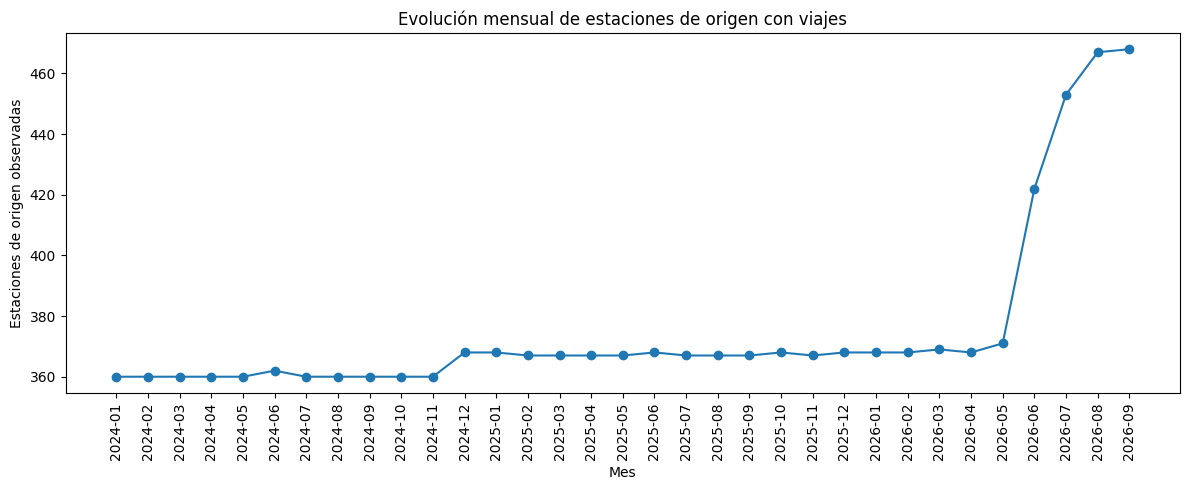

In [104]:
import matplotlib.pyplot as plt

monthly_coverage["month"] = (
    monthly_coverage["file"]
    .str.extract(r"(\d{4}_\d{2})")[0]
    .str.replace("_", "-", regex=False)
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_coverage["month"],
    monthly_coverage["origin_stations"],
    marker="o"
)

plt.xticks(rotation=90)
plt.xlabel("Mes")
plt.ylabel("Estaciones de origen observadas")
plt.title("Evolución mensual de estaciones de origen con viajes")
plt.tight_layout()
plt.show()

**Observación.** El número de estaciones de origen con viajes registrados se
mantiene relativamente estable durante 2024 y 2025. A partir de junio de 2026
se observa un incremento pronunciado en el número de estaciones presentes,
alcanzando más de 460 estaciones hacia el final del periodo.

Este comportamiento indica un cambio importante en el conjunto de estaciones
observadas. Con los datos disponibles no se puede determinar todavía si el
incremento corresponde exclusivamente a nuevas estaciones, reactivaciones u
otros cambios operativos.

Esta variación es relevante para P1 porque algunas estaciones presentes en el
periodo de evaluación podrían no contar con historial suficiente durante el
periodo de entrenamiento. Por ello, antes de construir las series horarias se
analizará la primera y última aparición de cada estación.

### 1.4 Primera aparición de las estaciones

El incremento en el número de estaciones observadas durante 2026 puede afectar
la capacidad del modelo para realizar predicciones sobre estaciones sin
historial previo.

Para identificar este posible problema de *cold start*, se calcula la primera
fecha en la que cada estación aparece como origen de un viaje y se compara con
los periodos propuestos de entrenamiento, validación y prueba.

In [105]:
station_activity = {}

for file in parquet_files:
    df_month = pd.read_parquet(
        file,
        columns=["inicio_del_viaje", "origen_id"]
    )

    activity_month = (
        df_month
        .groupby("origen_id")["inicio_del_viaje"]
        .agg(["min", "max"])
    )

    for station_id, row in activity_month.iterrows():

        if station_id not in station_activity:
            station_activity[station_id] = {
                "first_seen": row["min"],
                "last_seen": row["max"]
            }
        else:
            station_activity[station_id]["first_seen"] = min(
                station_activity[station_id]["first_seen"],
                row["min"]
            )

            station_activity[station_id]["last_seen"] = max(
                station_activity[station_id]["last_seen"],
                row["max"]
            )

station_activity = (
    pd.DataFrame.from_dict(station_activity, orient="index")
    .rename_axis("station_id")
    .reset_index()
)

station_activity.head()

,station_id,first_seen,last_seen
0,2,2024-01-01 08:50:17,2026-09-30 21:26:11
1,3,2024-01-01 05:00:32,2026-09-30 22:22:16
2,4,2024-01-01 07:57:29,2026-09-30 23:44:14
3,5,2024-01-01 10:32:47,2026-09-30 22:50:09
4,6,2024-01-01 08:53:53,2026-09-30 23:24:18


In [106]:
def classify_first_seen(date):
    if date < pd.Timestamp("2026-01-01"):
        return "Train"
    elif date < pd.Timestamp("2026-05-01"):
        return "Validation"
    else:
        return "Test"


station_activity["first_seen_split"] = (
    station_activity["first_seen"].apply(classify_first_seen)
)

station_activity["first_seen_split"].value_counts()

first_seen_split
Train    373
Test     100
Name: count, dtype: int64

In [107]:
test_new_stations = (
    station_activity[
        station_activity["first_seen_split"] == "Test"
    ]
    .sort_values("first_seen")
)

print(f"Estaciones observadas por primera vez en test: {len(test_new_stations)}")

test_new_stations.head(20)

Estaciones observadas por primera vez en test: 100


,station_id,first_seen,last_seen,first_seen_split
373,408,2026-05-19 15:22:13,2026-09-30 23:24:33,Test
375,410,2026-05-28 12:56:41,2026-09-30 22:55:48,Test
376,411,2026-05-28 14:01:32,2026-09-30 21:50:16,Test
374,409,2026-05-28 15:22:44,2026-09-30 20:43:34,Test
378,413,2026-05-29 12:12:15,2026-09-30 21:26:00,Test
381,416,2026-05-29 14:53:22,2026-09-30 18:50:26,Test
380,415,2026-05-30 05:31:13,2026-09-30 21:13:14,Test
379,414,2026-05-30 12:40:27,2026-09-30 21:48:53,Test
377,412,2026-05-30 13:39:46,2026-09-30 23:36:44,Test
384,419,2026-05-30 22:47:50,2026-09-30 22:15:46,Test


**Observación.** De las 473 estaciones observadas como origen durante el
periodo completo, 373 aparecen por primera vez durante el periodo de
entrenamiento (2024–2025), mientras que 100 aparecen por primera vez durante
el periodo de prueba (mayo–septiembre de 2026). No se identificaron estaciones
cuya primera aparición ocurriera durante el periodo de validación.

Esto confirma la presencia de un escenario de *cold start* en el conjunto de
prueba: algunas estaciones que deberán evaluarse no cuentan con historial
durante el entrenamiento.

Por esta razón, no se imputarán ceros para una estación antes de su primera
actividad observada. La construcción de la serie estación-hora deberá respetar
el periodo de actividad observado de cada estación.

Posteriormente, la evaluación de P1 podrá distinguir entre estaciones con
historial previo y estaciones nuevas para analizar el efecto del *cold start*
sobre el desempeño del modelo.

## 2. Exploración de la demanda horaria

### 2.1 Construcción de viajes iniciados por estación y hora

Para P1, la demanda se representa mediante el número de viajes que se inician
en cada estación durante cada hora.

A partir de los registros individuales de viajes se construye una serie
agregada por estación de origen y hora. En esta primera agregación únicamente
se incluyen combinaciones estación-hora en las que se observó al menos un
viaje. Las horas sin viajes se incorporarán posteriormente, una vez definido
el periodo de actividad observado de cada estación.

In [108]:
hourly_parts = []

for file in parquet_files:
    df_month = pd.read_parquet(
        file,
        columns=["inicio_del_viaje", "origen_id"]
    )

    df_month["hour"] = df_month["inicio_del_viaje"].dt.floor("h")

    hourly_month = (
        df_month
        .groupby(["origen_id", "hour"])
        .size()
        .reset_index(name="trips_started")
    )

    hourly_parts.append(hourly_month)

hourly_demand = pd.concat(hourly_parts, ignore_index=True)

hourly_demand = hourly_demand.rename(
    columns={"origen_id": "station_id"}
)

hourly_demand.head()

,station_id,hour,trips_started
0,2,2024-01-01 08:00:00,1
1,2,2024-01-01 09:00:00,1
2,2,2024-01-01 10:00:00,2
3,2,2024-01-01 12:00:00,2
4,2,2024-01-01 13:00:00,3


In [109]:
print(f"Filas estación-hora observadas: {len(hourly_demand):,}")
print(f"Estaciones: {hourly_demand['station_id'].nunique()}")
print(f"Fecha mínima: {hourly_demand['hour'].min()}")
print(f"Fecha máxima: {hourly_demand['hour'].max()}")

print(
    "Combinaciones estación-hora duplicadas:",
    hourly_demand.duplicated(["station_id", "hour"]).sum()
)

hourly_demand["trips_started"].describe()

Filas estación-hora observadas: 4,216,021
Estaciones: 473
Fecha mínima: 2024-01-01 00:00:00
Fecha máxima: 2026-09-30 23:00:00
Combinaciones estación-hora duplicadas: 0


count    4.216021e+06
mean     2.974193e+00
std      3.032127e+00
min      1.000000e+00
25%      1.000000e+00
50%      2.000000e+00
75%      4.000000e+00
max      2.070000e+02
Name: trips_started, dtype: float64

### 2.2 Incorporación de horas sin viajes

La agregación inicial contiene únicamente horas en las que se registró al menos
un viaje. Sin embargo, para un problema de predicción de demanda, las horas con
cero viajes también constituyen observaciones válidas.

Para evitar asignar demanda cero a periodos en los que una estación todavía no
había sido observada, se construye una serie horaria independiente para cada
estación entre su primera y última actividad observada.

Las horas ausentes dentro de este intervalo se interpretan como horas con cero
viajes. La primera y última actividad observadas se utilizan como una
aproximación del periodo de actividad disponible en los datos y no como fechas
oficiales de apertura o cierre de las estaciones.

In [110]:
complete_parts = []

for station_id, station_data in hourly_demand.groupby("station_id"):

    station_data = (
        station_data
        .sort_values("hour")
        .set_index("hour")
    )

    full_hours = pd.date_range(
        start=station_data.index.min(),
        end=station_data.index.max(),
        freq="h"
    )

    station_complete = (
        station_data
        .reindex(full_hours)
        .rename_axis("hour")
        .reset_index()
    )

    station_complete["station_id"] = station_id
    station_complete["trips_started"] = (
        station_complete["trips_started"]
        .fillna(0)
        .astype("int32")
    )

    complete_parts.append(station_complete)

hourly_complete = pd.concat(
    complete_parts,
    ignore_index=True
)

hourly_complete.head()

,hour,station_id,trips_started
0,2024-01-01 08:00:00,2,1
1,2024-01-01 09:00:00,2,1
2,2024-01-01 10:00:00,2,2
3,2024-01-01 11:00:00,2,0
4,2024-01-01 12:00:00,2,2


In [111]:
zero_hours = (hourly_complete["trips_started"] == 0).sum()
total_hours = len(hourly_complete)

print(f"Filas estación-hora completas: {total_hours:,}")
print(f"Horas con cero viajes: {zero_hours:,}")
print(f"Porcentaje de horas con cero viajes: {zero_hours / total_hours:.2%}")
print(
    "Duplicados estación-hora:",
    hourly_complete.duplicated(["station_id", "hour"]).sum()
)

hourly_complete["trips_started"].describe()

Filas estación-hora completas: 9,045,247
Horas con cero viajes: 4,829,226
Porcentaje de horas con cero viajes: 53.39%
Duplicados estación-hora: 0


count    9.045247e+06
mean     1.386282e+00
std      2.546871e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      2.000000e+00
max      2.070000e+02
Name: trips_started, dtype: float64

**Observación.** Después de completar la serie horaria dentro del periodo de
actividad observado de cada estación, se obtuvieron 9,045,247 observaciones
estación-hora. De ellas, 4,829,226 (53.39 %) corresponden a horas sin viajes
iniciados.

La incorporación de estas observaciones modifica considerablemente la
distribución de la variable objetivo. La mediana disminuye de 2 a 0 viajes
por hora y la media de aproximadamente 2.97 a 1.39 viajes por hora.

Esto muestra que la demanda horaria presenta una alta frecuencia de ceros,
por lo que estos casos deben conservarse durante el entrenamiento y la
evaluación. También será importante complementar las métricas globales con
un análisis del desempeño en periodos de mayor demanda.

In [112]:
top_demand = (
    hourly_complete
    .nlargest(20, "trips_started")
    [["station_id", "hour", "trips_started"]]
)

top_demand

,station_id,hour,trips_started
4229068,194,2025-09-20 21:00:00,207
4229067,194,2025-09-20 20:00:00,178
4233771,194,2026-04-04 20:00:00,149
4237468,194,2026-09-05 21:00:00,141
4233772,194,2026-04-04 21:00:00,132
4232427,194,2026-02-07 20:00:00,124
4232428,194,2026-02-07 21:00:00,121
4237467,194,2026-09-05 20:00:00,111
4230076,194,2025-11-01 21:00:00,109
4233099,194,2026-03-07 20:00:00,109


In [113]:
for threshold in [20, 30, 50, 100]:
    count = (hourly_complete["trips_started"] > threshold).sum()

    print(
        f"Horas con más de {threshold:3d} viajes: "
        f"{count:,} ({count / len(hourly_complete):.4%})"
    )

Horas con más de  20 viajes: 13,629 (0.1507%)
Horas con más de  30 viajes: 3,229 (0.0357%)
Horas con más de  50 viajes: 555 (0.0061%)
Horas con más de 100 viajes: 15 (0.0002%)


**Observación.** La distribución de la demanda presenta una cola derecha con
valores elevados poco frecuentes. Solo el 0.1507 % de las observaciones supera
20 viajes iniciados por hora, mientras que únicamente 15 observaciones
(0.0002 %) superan 100 viajes.

Los valores más altos no aparecen distribuidos aleatoriamente: varios se
concentran en la estación 194 y en horarios cercanos a las 20:00–21:00 en
distintas fechas. Este patrón sugiere que los valores extremos podrían
corresponder a comportamientos reales de demanda y no necesariamente a errores.

Por lo tanto, en esta etapa no se eliminan estas observaciones. Se conservarán
para el modelado mientras no exista evidencia de que correspondan a registros
inválidos.

In [114]:
hourly_complete["hour_of_day"] = hourly_complete["hour"].dt.hour

demand_by_hour = (
    hourly_complete
    .groupby("hour_of_day")["trips_started"]
    .agg(["mean", "median"])
    .reset_index()
)

demand_by_hour

,hour_of_day,mean,median
0,0,0.213849,0.0
1,1,0.000316,0.0
2,2,0.000027,0.0
3,3,0.000003,0.0
4,4,0.000024,0.0
5,5,0.265368,0.0
6,6,0.932179,0.0
7,7,1.850683,1.0
8,8,2.582122,2.0
9,9,1.861349,1.0


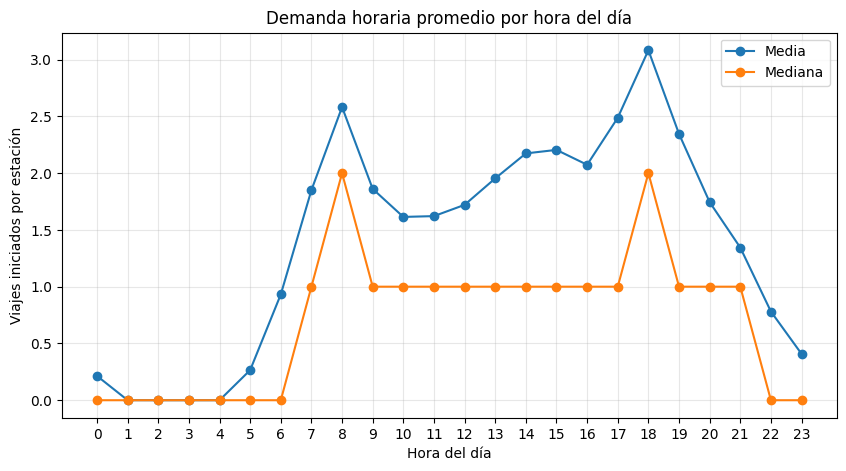

In [115]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    demand_by_hour["hour_of_day"],
    demand_by_hour["mean"],
    marker="o",
    label="Media"
)

plt.plot(
    demand_by_hour["hour_of_day"],
    demand_by_hour["median"],
    marker="o",
    label="Mediana"
)

plt.xlabel("Hora del día")
plt.ylabel("Viajes iniciados por estación")
plt.title("Demanda horaria promedio por hora del día")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [116]:
hourly_complete["day_of_week"] = hourly_complete["hour"].dt.dayofweek

day_names = {
    0: "Lunes",
    1: "Martes",
    2: "Miércoles",
    3: "Jueves",
    4: "Viernes",
    5: "Sábado",
    6: "Domingo"
}

demand_by_day = (
    hourly_complete
    .groupby("day_of_week")["trips_started"]
    .agg(["mean", "median"])
    .reset_index()
)

demand_by_day["day"] = demand_by_day["day_of_week"].map(day_names)

demand_by_day[["day", "mean", "median"]]

KeyboardInterrupt: 

**Observación.** La demanda presenta un patrón intradía claramente definido.
Se observa un primer pico alrededor de las 08:00 y un segundo pico, de mayor
magnitud, alrededor de las 18:00. Durante la madrugada la demanda es muy baja
y comienza a incrementarse rápidamente a partir de las 06:00–07:00.

Estos resultados respaldan el uso de la hora del día como variable predictora.
Además, aunque inicialmente se había considerado como periodo de interés el
intervalo de 07:00–09:00, la exploración muestra que el periodo vespertino,
especialmente alrededor de las 17:00–19:00, también representa un intervalo
relevante de alta demanda.

También se observan diferencias según el día de la semana. La demanda promedio
es mayor entre martes y jueves y disminuye durante el fin de semana,
particularmente el domingo. Esto respalda la incorporación de variables como
`day_of_week` e `is_weekend` en el conjunto de características.

In [ ]:
demand_day_hour = (
    hourly_complete
    .groupby(["day_of_week", "hour_of_day"])["trips_started"]
    .mean()
    .unstack()
)

demand_day_hour.index = demand_day_hour.index.map(day_names)

demand_day_hour.round(2)

hour_of_day,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
day_of_week,,,,,,,,,,,,,,,,,,,,,
Lunes,0.14,0.0,0.0,0.0,0.0,0.30,1.08,2.14,2.90,1.86,...,2.19,2.31,2.25,2.89,3.77,2.72,1.88,1.38,0.72,0.32
Martes,0.12,0.0,0.0,0.0,0.0,0.34,1.21,2.42,3.28,2.07,...,2.30,2.46,2.41,3.14,4.01,2.87,2.00,1.45,0.78,0.39
Miércoles,0.17,0.0,0.0,0.0,0.0,0.33,1.20,2.39,3.25,2.02,...,2.27,2.47,2.40,3.10,4.00,2.89,2.01,1.51,0.82,0.41
Jueves,0.19,0.0,0.0,0.0,0.0,0.32,1.17,2.33,3.16,2.02,...,2.26,2.43,2.37,3.04,3.89,2.77,1.98,1.49,0.87,0.45
Viernes,0.23,0.0,0.0,0.0,0.0,0.29,1.05,2.18,2.99,1.95,...,2.31,2.49,2.38,2.78,3.36,2.54,1.85,1.40,0.87,0.50
Sábado,0.32,0.0,0.0,0.0,0.0,0.16,0.49,0.93,1.39,1.39,...,2.41,1.97,1.60,1.42,1.43,1.48,1.41,1.23,0.82,0.49
Domingo,0.33,0.0,0.0,0.0,0.0,0.12,0.33,0.56,1.09,1.71,...,1.47,1.30,1.09,1.03,1.10,1.15,1.07,0.95,0.59,0.30


In [ ]:
peak_day_hours = (
    hourly_complete
    .groupby(["day_of_week", "hour_of_day"])["trips_started"]
    .mean()
    .reset_index(name="mean_trips")
    .sort_values("mean_trips", ascending=False)
)

peak_day_hours["day"] = peak_day_hours["day_of_week"].map(day_names)

peak_day_hours[
    ["day", "hour_of_day", "mean_trips"]
].head(15)

,day,hour_of_day,mean_trips
42,Martes,18,4.010405
66,Miércoles,18,3.995287
90,Jueves,18,3.891459
18,Lunes,18,3.771868
114,Viernes,18,3.355400
32,Martes,8,3.280194
56,Miércoles,8,3.249492
80,Jueves,8,3.159897
41,Martes,17,3.138931
65,Miércoles,17,3.103945


**Interacción entre día y hora.** Al analizar conjuntamente el día de la semana
y la hora del día, los periodos de mayor demanda se concentran principalmente
en días laborales.

El patrón más intenso ocurre alrededor de las 18:00, particularmente de martes
a jueves, con promedios cercanos o superiores a 4 viajes iniciados por
estación-hora. También se identifica un segundo periodo de alta demanda
alrededor de las 08:00 durante estos mismos días.

La combinación de ambos patrones confirma que la demanda depende no solo de la
hora o del día de forma independiente, sino también de su interacción. Por lo
tanto, las variables temporales `hour_of_day`, `day_of_week` e `is_weekend`
son candidatas relevantes para el modelo P1.

Los resultados también amplían el planteamiento inicial del ML Canvas: además
del periodo matutino de 07:00–09:00, el intervalo vespertino de aproximadamente
17:00–19:00 representa un periodo crítico de demanda que deberá considerarse
durante la evaluación del modelo.

In [ ]:
lag_analysis = (
    hourly_complete[
        ["station_id", "hour", "trips_started"]
    ]
    .sort_values(["station_id", "hour"])
    .copy()
)

for lag in [1, 24, 168]:
    lag_analysis[f"lag_{lag}"] = (
        lag_analysis
        .groupby("station_id")["trips_started"]
        .shift(lag)
    )

lag_analysis.head()

,station_id,hour,trips_started,lag_1,lag_24,lag_168
0,2,2024-01-01 08:00:00,1,NaN,NaN,NaN
1,2,2024-01-01 09:00:00,1,1.0,NaN,NaN
2,2,2024-01-01 10:00:00,2,1.0,NaN,NaN
3,2,2024-01-01 11:00:00,0,2.0,NaN,NaN
4,2,2024-01-01 12:00:00,2,0.0,NaN,NaN


In [ ]:
lag_correlations = (
    lag_analysis[
        ["trips_started", "lag_1", "lag_24", "lag_168"]
    ]
    .corr()["trips_started"]
    .drop("trips_started")
    .sort_values(ascending=False)
)

lag_correlations

lag_168    0.719150
lag_1      0.661032
lag_24     0.649439
Name: trips_started, dtype: float64

In [ ]:
lag_missing = lag_analysis[
    ["lag_1", "lag_24", "lag_168"]
].isna().sum()

lag_missing_pct = (
    lag_missing / len(lag_analysis) * 100
)

pd.DataFrame({
    "missing_rows": lag_missing,
    "missing_pct": lag_missing_pct
})

,missing_rows,missing_pct
lag_1,473,0.005229
lag_24,11329,0.125248
lag_168,79297,0.876670


### 2.3 Dependencia temporal de la demanda

Para evaluar si el historial reciente de cada estación puede aportar información
predictiva, se analizaron tres rezagos de la variable objetivo:

- `lag_1`: demanda observada una hora antes.
- `lag_24`: demanda observada 24 horas antes.
- `lag_168`: demanda observada 168 horas antes, equivalente a una semana.

Los tres rezagos presentan una asociación positiva con la demanda actual.
`lag_168` muestra la correlación más alta (0.719), seguido de `lag_1` (0.661)
y `lag_24` (0.649).

El resultado de `lag_168` es consistente con los patrones semanales observados
durante la exploración, ya que permite comparar una estación con su demanda
durante el mismo día de la semana y la misma hora de la semana anterior.

Los valores faltantes generados por estos rezagos representan una proporción
pequeña del conjunto completo: aproximadamente 0.005 % para `lag_1`, 0.125 %
para `lag_24` y 0.877 % para `lag_168`. Estos valores aparecen principalmente
al inicio del historial disponible de cada estación.

Por lo tanto, los tres rezagos se mantienen como características candidatas
para el modelo P1.

In [ ]:
rolling_analysis = (
    hourly_complete[
        ["station_id", "hour", "trips_started"]
    ]
    .sort_values(["station_id", "hour"])
    .copy()
)

rolling_analysis["rolling_mean_3h"] = (
    rolling_analysis
    .groupby("station_id")["trips_started"]
    .transform(
        lambda x: x.shift(1).rolling(window=3).mean()
    )
)

rolling_analysis["rolling_mean_24h"] = (
    rolling_analysis
    .groupby("station_id")["trips_started"]
    .transform(
        lambda x: x.shift(1).rolling(window=24).mean()
    )
)

rolling_analysis[
    ["trips_started", "rolling_mean_3h", "rolling_mean_24h"]
].corr()["trips_started"]

trips_started       1.000000
rolling_mean_3h     0.631171
rolling_mean_24h    0.524785
Name: trips_started, dtype: float64

**Promedios móviles.** También se evaluaron características que resumen el
comportamiento reciente de cada estación. El promedio móvil de las tres horas
anteriores (`rolling_mean_3h`) presenta una correlación de 0.631 con la demanda
actual, mientras que el promedio de las 24 horas anteriores
(`rolling_mean_24h`) presenta una correlación de 0.525.

Ambas variables aportan una representación complementaria a los rezagos:
mientras los `lags` describen momentos específicos del pasado, los promedios
móviles resumen el nivel reciente de actividad de la estación.

Para evitar fuga de información, los promedios móviles se calculan después de
desplazar la serie una hora (`shift(1)`), garantizando que la demanda de la hora
que se desea predecir no forme parte del cálculo.

Por lo tanto, `rolling_mean_3h` y `rolling_mean_24h` se mantienen como
características candidatas para P1.

## 3. Preparación del conjunto de modelado

### 3.1 Partición temporal

Debido a la naturaleza temporal del problema, los datos se dividen
cronológicamente para evitar utilizar información futura durante el
entrenamiento.

Se propone la siguiente partición:

- **Entrenamiento:** enero de 2024 a diciembre de 2025.
- **Validación:** enero a abril de 2026.
- **Prueba:** mayo a septiembre de 2026.

El conjunto de prueba presenta además un escenario relevante de *cold start*,
ya que 100 estaciones presentan su primera actividad observada durante este periodo. Esto permitirá analizar posteriormente el desempeño del modelo tanto
en estaciones con historial previo como en estaciones nuevas.

In [ ]:
station_activity_any = []

for file in parquet_files:
    df_month = pd.read_parquet(
        file,
        columns=[
            "inicio_del_viaje",
            "fin_del_viaje",
            "origen_id",
            "destino_id"
        ]
    )

    origin_activity = (
        df_month
        .groupby("origen_id")
        .agg(
            first_activity=("inicio_del_viaje", "min"),
            last_activity=("inicio_del_viaje", "max")
        )
        .rename_axis("station_id")
        .reset_index()
    )

    destination_activity = (
        df_month
        .groupby("destino_id")
        .agg(
            first_activity=("fin_del_viaje", "min"),
            last_activity=("fin_del_viaje", "max")
        )
        .rename_axis("station_id")
        .reset_index()
    )

    station_activity_any.append(origin_activity)
    station_activity_any.append(destination_activity)

station_activity_any = (
    pd.concat(station_activity_any, ignore_index=True)
    .groupby("station_id", as_index=False)
    .agg(
        first_activity=("first_activity", "min"),
        last_activity=("last_activity", "max")
    )
)

station_activity_any.shape

(473, 3)

In [ ]:
print(
    "Estaciones con cualquier actividad:",
    station_activity_any["station_id"].nunique()
)

print(
    "Estaciones observadas como origen:",
    station_activity["station_id"].nunique()
)

station_activity_any.head()

Estaciones con cualquier actividad: 473
Estaciones observadas como origen: 473


,station_id,first_activity,last_activity
0,2,2024-01-01 07:25:44,2026-09-30 21:26:11
1,3,2024-01-01 05:00:32,2026-09-30 23:58:41
2,4,2024-01-01 07:57:29,2026-09-30 23:44:14
3,5,2024-01-01 10:32:47,2026-09-30 22:54:39
4,6,2024-01-01 08:53:53,2026-10-01 00:08:02


In [ ]:
activity_comparison = (
    station_activity[
        ["station_id", "first_seen", "last_seen"]
    ]
    .merge(
        station_activity_any,
        on="station_id",
        how="left"
    )
)

activity_comparison["first_diff_hours"] = (
    activity_comparison["first_seen"]
    - activity_comparison["first_activity"]
).dt.total_seconds() / 3600

activity_comparison["last_diff_hours"] = (
    activity_comparison["last_activity"]
    - activity_comparison["last_seen"]
).dt.total_seconds() / 3600

activity_comparison[
    ["first_diff_hours", "last_diff_hours"]
].describe()

,first_diff_hours,last_diff_hours
count,473.000000,473.000000
mean,2.806448,0.777017
std,6.958341,1.564196
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.001944,0.000000
75%,2.312222,0.942500
max,83.669167,14.677778


In [ ]:
print(
    "Estaciones cuya primera actividad ocurre antes de su primera salida:",
    (activity_comparison["first_diff_hours"] > 0).sum()
)

print(
    "Estaciones cuya última actividad ocurre después de su última salida:",
    (activity_comparison["last_diff_hours"] > 0).sum()
)

print(
    "Mayor diferencia inicial (horas):",
    activity_comparison["first_diff_hours"].max()
)

print(
    "Mayor diferencia final (horas):",
    activity_comparison["last_diff_hours"].max()
)

Estaciones cuya primera actividad ocurre antes de su primera salida: 240
Estaciones cuya última actividad ocurre después de su última salida: 222
Mayor diferencia inicial (horas): 83.66916666666667
Mayor diferencia final (horas): 14.677777777777777


### 3.2 Definición del periodo de actividad de las estaciones

La primera exploración construyó la serie horaria utilizando la primera y
última salida observadas de cada estación. Posteriormente se incorporaron
también las llegadas para obtener una aproximación más completa del periodo
durante el cual existe evidencia de actividad de cada estación.

De las 473 estaciones, 240 presentan al menos una llegada anterior a su
primera salida observada y 222 presentan actividad de llegada posterior a su
última salida. La diferencia máxima al inicio alcanza aproximadamente 83.67
horas.

Por esta razón, el conjunto de modelado utiliza como ventana de actividad el
intervalo comprendido entre la primera y última actividad observadas,
considerando tanto salidas como llegadas. Esta ventana representa actividad
observada en los datos y no necesariamente las fechas oficiales de apertura
o cierre de una estación.

La variable objetivo continúa siendo exclusivamente el número de viajes
iniciados por estación y hora. Las llegadas se utilizan únicamente para
delimitar el periodo de actividad observado.

In [ ]:
DATA_START = pd.Timestamp("2024-01-01 00:00:00")
DATA_END = pd.Timestamp("2026-09-30 23:00:00")

In [ ]:
complete_parts_final = []

for row in station_activity_any.itertuples(index=False):

    station_id = row.station_id

    start_hour = max(
        row.first_activity.floor("h"),
        DATA_START
    )

    end_hour = min(
        row.last_activity.floor("h"),
        DATA_END
    )

    full_hours = pd.date_range(
        start=start_hour,
        end=end_hour,
        freq="h"
    )

    station_complete = pd.DataFrame({
        "station_id": station_id,
        "hour": full_hours
    })

    station_demand = hourly_demand[
        hourly_demand["station_id"] == station_id
    ][["hour", "trips_started"]]

    station_complete = station_complete.merge(
        station_demand,
        on="hour",
        how="left"
    )

    station_complete["trips_started"] = (
        station_complete["trips_started"]
        .fillna(0)
        .astype("int32")
    )

    complete_parts_final.append(station_complete)

hourly_model = (
    pd.concat(complete_parts_final, ignore_index=True)
    .sort_values(["station_id", "hour"])
    .reset_index(drop=True)
)

In [ ]:
print(f"Filas finales: {len(hourly_model):,}")
print(f"Estaciones: {hourly_model['station_id'].nunique()}")
print(f"Fecha mínima: {hourly_model['hour'].min()}")
print(f"Fecha máxima: {hourly_model['hour'].max()}")

print(
    "Duplicados estación-hora:",
    hourly_model.duplicated(["station_id", "hour"]).sum()
)

print(
    "Horas con cero viajes:",
    f"{(hourly_model['trips_started'] == 0).sum():,}"
)

print(
    "Porcentaje de ceros:",
    f"{(hourly_model['trips_started'] == 0).mean():.2%}"
)

print()
print(
    "Total de viajes recuperados:",
    f"{hourly_model['trips_started'].sum():,}"
)

print(
    "Total de viajes procesados:",
    f"{total_rows:,}"
)

print(
    "Diferencia:",
    f"{total_rows - hourly_model['trips_started'].sum():,}"
)

Filas finales: 9,046,917
Estaciones: 473
Fecha mínima: 2024-01-01 00:00:00
Fecha máxima: 2026-09-30 23:00:00
Duplicados estación-hora: 0
Horas con cero viajes: 4,830,896
Porcentaje de ceros: 53.40%

Total de viajes recuperados: 12,539,260
Total de viajes procesados: 12,539,260
Diferencia: 0


**Validación de la serie horaria final.** La serie completa contiene
9,046,917 observaciones correspondientes a 473 estaciones. No se detectaron
duplicados para la combinación estación-hora.

Al completar las horas sin salidas dentro de la ventana de actividad observada,
4,830,896 registros presentan demanda igual a cero, equivalentes al 53.40 %
del conjunto.

Como control de integridad, la suma de `trips_started` en la serie horaria es
12,539,260, exactamente igual al número de viajes presentes en los archivos
procesados. Por lo tanto, la transformación conserva la totalidad de los
viajes utilizados para P1.

La ventana de actividad se utiliza únicamente para determinar en qué periodos
es razonable completar horas sin salidas con valor cero.

In [ ]:
modeling_data = hourly_model.copy()

modeling_data["split"] = pd.cut(
    modeling_data["hour"],
    bins=[
        pd.Timestamp.min,
        pd.Timestamp("2026-01-01"),
        pd.Timestamp("2026-05-01"),
        pd.Timestamp.max
    ],
    labels=["train", "validation", "test"],
    right=False
)

split_summary_final = (
    modeling_data
    .groupby("split", observed=True)
    .agg(
        rows=("trips_started", "size"),
        stations=("station_id", "nunique"),
        start=("hour", "min"),
        end=("hour", "max"),
        mean_trips=("trips_started", "mean"),
        zero_pct=("trips_started", lambda x: (x == 0).mean() * 100)
    )
)

split_summary_final

,rows,stations,start,end,mean_trips,zero_pct
split,,,,,,
train,6401364,373,2024-01-01,2025-12-31 23:00:00,1.433750,52.458929
validation,1068480,371,2026-01-01,2026-04-30 23:00:00,1.328083,54.338125
test,1577073,471,2026-05-01,2026-09-30 23:00:00,1.231571,56.574236


In [ ]:
TEST_START = pd.Timestamp("2026-05-01")

cold_start_stations_final = set(
    station_activity_any.loc[
        station_activity_any["first_activity"] >= TEST_START,
        "station_id"
    ]
)

print(
    "Estaciones cold-start según cualquier actividad:",
    len(cold_start_stations_final)
)

test_data_final = modeling_data[
    modeling_data["split"] == "test"
].copy()

test_data_final["station_group"] = (
    test_data_final["station_id"]
    .isin(cold_start_stations_final)
    .map({
        True: "cold_start",
        False: "established"
    })
)

cold_start_summary_final = (
    test_data_final
    .groupby("station_group")
    .agg(
        rows=("trips_started", "size"),
        stations=("station_id", "nunique"),
        mean_trips=("trips_started", "mean"),
        zero_pct=("trips_started", lambda x: (x == 0).mean() * 100)
    )
)

cold_start_summary_final

Estaciones cold-start según cualquier actividad: 100


,rows,stations,mean_trips,zero_pct
station_group,,,,
cold_start,215958,100,0.456964,74.389002
established,1361115,371,1.354472,53.747699


### 3.3 Características de la partición temporal

La partición final contiene 6,401,364 observaciones para entrenamiento,
1,068,480 para validación y 1,577,073 para prueba. El porcentaje de horas
sin viajes aumenta de 52.46 % en entrenamiento a 54.34 % en validación y
56.57 % en prueba, mientras que la demanda media disminuye ligeramente
durante los periodos posteriores.

El conjunto de prueba contiene 100 estaciones cuya primera actividad observada
ocurre a partir de mayo de 2026. Estas estaciones presentan una demanda media
de 0.46 viajes por hora y aproximadamente 74.39 % de horas sin viajes, mientras
que las estaciones con historial previo presentan una demanda media de 1.35
viajes por hora y 53.75 % de horas sin viajes.

Debido a estas diferencias, la evaluación final considerará tanto el desempeño
global del modelo como su comportamiento por separado en estaciones
establecidas y estaciones de tipo `cold_start`.

## 4. Construcción de características para P1

A partir de la serie horaria validada se construyen las características
candidatas para el modelo de regresión de P1.

Cada observación representa una combinación estación-hora y la variable
objetivo `trips_started` corresponde al número de viajes iniciados durante
esa hora.

Las características se construyen respetando el orden temporal y utilizando
únicamente información que estaría disponible antes de la hora que se desea
predecir.

### 4.1 Características de calendario

La exploración mostró patrones temporales asociados con la hora del día y el
día de la semana. Por esta razón se incorporan variables de calendario que
pueden conocerse antes del momento de predicción y no generan fuga de
información.

In [ ]:
features_p1 = (
    hourly_model
    .sort_values(["station_id", "hour"])
    .copy()
)

features_p1["hour_of_day"] = features_p1["hour"].dt.hour
features_p1["day_of_week"] = features_p1["hour"].dt.dayofweek
features_p1["is_weekend"] = (
    features_p1["day_of_week"] >= 5
).astype("int8")
features_p1["month"] = features_p1["hour"].dt.month

In [ ]:
features_p1[
    [
        "station_id",
        "hour",
        "trips_started",
        "hour_of_day",
        "day_of_week",
        "is_weekend",
        "month"
    ]
].head(10)

,station_id,hour,trips_started,hour_of_day,day_of_week,is_weekend,month
0,2,2024-01-01 07:00:00,0,7,0,0,1
1,2,2024-01-01 08:00:00,1,8,0,0,1
2,2,2024-01-01 09:00:00,1,9,0,0,1
3,2,2024-01-01 10:00:00,2,10,0,0,1
4,2,2024-01-01 11:00:00,0,11,0,0,1
5,2,2024-01-01 12:00:00,2,12,0,0,1
6,2,2024-01-01 13:00:00,3,13,0,0,1
7,2,2024-01-01 14:00:00,2,14,0,0,1
8,2,2024-01-01 15:00:00,1,15,0,0,1
9,2,2024-01-01 16:00:00,1,16,0,0,1


### 4.2 Características históricas

Además de los patrones de calendario, la exploración mostró una relación entre
la demanda actual de una estación y su demanda observada en periodos anteriores.

Para incorporar esta información sin generar fuga de datos, las características
históricas se construyen utilizando exclusivamente valores anteriores a la hora
que se desea predecir.

Primero se analiza `lag_1`, que representa el número de viajes iniciados en la
misma estación durante la hora inmediatamente anterior.

In [ ]:
features_p1["lag_1"] = (
    features_p1
    .groupby("station_id")["trips_started"]
    .shift(1)
)

In [ ]:
example_station = features_p1["station_id"].iloc[0]

features_p1.loc[
    features_p1["station_id"] == example_station,
    [
        "station_id",
        "hour",
        "trips_started",
        "lag_1"
    ]
].head(10)

,station_id,hour,trips_started,lag_1
0,2,2024-01-01 07:00:00,0,NaN
1,2,2024-01-01 08:00:00,1,0.0
2,2,2024-01-01 09:00:00,1,1.0
3,2,2024-01-01 10:00:00,2,1.0
4,2,2024-01-01 11:00:00,0,2.0
5,2,2024-01-01 12:00:00,2,0.0
6,2,2024-01-01 13:00:00,3,2.0
7,2,2024-01-01 14:00:00,2,3.0
8,2,2024-01-01 15:00:00,1,2.0
9,2,2024-01-01 16:00:00,1,1.0


In [ ]:
features_p1["lag_24"] = (
    features_p1
    .groupby("station_id")["trips_started"]
    .shift(24)
)

In [ ]:
features_p1.loc[
    features_p1["station_id"] == example_station,
    [
        "station_id",
        "hour",
        "trips_started",
        "lag_1",
        "lag_24"
    ]
].head(30)

,station_id,hour,trips_started,lag_1,lag_24
0,2,2024-01-01 07:00:00,0,NaN,NaN
1,2,2024-01-01 08:00:00,1,0.0,NaN
2,2,2024-01-01 09:00:00,1,1.0,NaN
3,2,2024-01-01 10:00:00,2,1.0,NaN
4,2,2024-01-01 11:00:00,0,2.0,NaN
5,2,2024-01-01 12:00:00,2,0.0,NaN
6,2,2024-01-01 13:00:00,3,2.0,NaN
7,2,2024-01-01 14:00:00,2,3.0,NaN
8,2,2024-01-01 15:00:00,1,2.0,NaN
9,2,2024-01-01 16:00:00,1,1.0,NaN


In [ ]:
features_p1["lag_168"] = (
    features_p1
    .groupby("station_id")["trips_started"]
    .shift(168)
)

In [ ]:
station_example = features_p1.loc[
    features_p1["station_id"] == example_station,
    [
        "station_id",
        "hour",
        "trips_started",
        "lag_168"
    ]
].reset_index(drop=True)

station_example.iloc[165:172]

,station_id,hour,trips_started,lag_168
165,2,2024-01-08 04:00:00,0,NaN
166,2,2024-01-08 05:00:00,1,NaN
167,2,2024-01-08 06:00:00,8,NaN
168,2,2024-01-08 07:00:00,8,0.0
169,2,2024-01-08 08:00:00,13,1.0
170,2,2024-01-08 09:00:00,12,1.0
171,2,2024-01-08 10:00:00,4,2.0


### 4.3 Promedios móviles

Además de valores específicos del pasado, se incorporan características que
resumen el nivel reciente de demanda de cada estación.

Para evitar fuga de información, primero se desplaza la serie una hora y
posteriormente se calcula el promedio móvil. De esta forma, la demanda de la
hora que se desea predecir nunca participa en la construcción de la
característica.

In [ ]:
features_p1["rolling_mean_3h"] = (
    features_p1
    .groupby("station_id")["trips_started"]
    .transform(
        lambda x: x.shift(1).rolling(window=3).mean()
    )
)

In [ ]:
features_p1.loc[
    features_p1["station_id"] == example_station,
    [
        "station_id",
        "hour",
        "trips_started",
        "lag_1",
        "rolling_mean_3h"
    ]
].head(10)

,station_id,hour,trips_started,lag_1,rolling_mean_3h
0,2,2024-01-01 07:00:00,0,NaN,NaN
1,2,2024-01-01 08:00:00,1,0.0,NaN
2,2,2024-01-01 09:00:00,1,1.0,NaN
3,2,2024-01-01 10:00:00,2,1.0,0.666667
4,2,2024-01-01 11:00:00,0,2.0,1.333333
5,2,2024-01-01 12:00:00,2,0.0,1.000000
6,2,2024-01-01 13:00:00,3,2.0,1.333333
7,2,2024-01-01 14:00:00,2,3.0,1.666667
8,2,2024-01-01 15:00:00,1,2.0,2.333333
9,2,2024-01-01 16:00:00,1,1.0,2.000000


In [ ]:
features_p1["rolling_mean_24h"] = (
    features_p1
    .groupby("station_id")["trips_started"]
    .transform(
        lambda x: x.shift(1).rolling(window=24).mean()
    )
)

In [ ]:
features_p1.loc[
    features_p1["station_id"] == example_station,
    [
        "station_id",
        "hour",
        "trips_started",
        "rolling_mean_24h"
    ]
].iloc[21:28]

,station_id,hour,trips_started,rolling_mean_24h
21,2,2024-01-02 04:00:00,0,NaN
22,2,2024-01-02 05:00:00,0,NaN
23,2,2024-01-02 06:00:00,5,NaN
24,2,2024-01-02 07:00:00,11,1.166667
25,2,2024-01-02 08:00:00,10,1.625000
26,2,2024-01-02 09:00:00,6,2.000000
27,2,2024-01-02 10:00:00,6,2.208333


### 4.4 Auditoría de características históricas

Las características históricas requieren una cantidad mínima de observaciones
previas para poder calcularse. Por esta razón, las primeras horas observadas
de cada estación pueden contener valores faltantes.

Antes de definir su tratamiento para el modelado, se cuantifica la cantidad
de valores faltantes generados por cada característica.

In [ ]:
historical_features = [
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_3h",
    "rolling_mean_24h"
]

missing_features = pd.DataFrame({
    "missing": features_p1[historical_features].isna().sum(),
    "missing_pct": (
        features_p1[historical_features].isna().mean() * 100
    )
})

missing_features

,missing,missing_pct
lag_1,473,0.005228
lag_24,11330,0.125236
lag_168,79298,0.876520
rolling_mean_3h,1418,0.015674
rolling_mean_24h,11330,0.125236


In [ ]:
features_p1["split"] = pd.cut(
    features_p1["hour"],
    bins=[
        pd.Timestamp.min,
        pd.Timestamp("2026-01-01"),
        pd.Timestamp("2026-05-01"),
        pd.Timestamp.max
    ],
    labels=["train", "validation", "test"],
    right=False
)

In [ ]:
features_p1["has_missing_history"] = (
    features_p1[historical_features]
    .isna()
    .any(axis=1)
)

In [ ]:
missing_by_split = (
    features_p1
    .groupby("split", observed=True)
    .agg(
        rows=("trips_started", "size"),
        rows_missing_history=("has_missing_history", "sum")
    )
)

missing_by_split["missing_pct"] = (
    missing_by_split["rows_missing_history"]
    / missing_by_split["rows"]
    * 100
)

missing_by_split

,rows,rows_missing_history,missing_pct
split,,,
train,6401364,62664,0.978916
validation,1068480,0,0.000000
test,1577073,16634,1.054739


In [ ]:
cold_start_stations = set(
    station_activity_any.loc[
        station_activity_any["first_activity"] >= pd.Timestamp("2026-05-01"),
        "station_id"
    ]
)

test_missing = features_p1.loc[
    (features_p1["split"] == "test")
    & (features_p1["has_missing_history"])
]

missing_cold_start_audit = pd.Series({
    "rows_test_missing": len(test_missing),
    "stations_test_missing": test_missing["station_id"].nunique(),
    "rows_from_cold_start": test_missing["station_id"].isin(cold_start_stations).sum(),
    "cold_start_stations_with_missing": (
        test_missing.loc[
            test_missing["station_id"].isin(cold_start_stations),
            "station_id"
        ].nunique()
    )
})

missing_cold_start_audit

rows_test_missing                   16634
stations_test_missing                 100
rows_from_cold_start                16634
cold_start_stations_with_missing      100
dtype: int64

#### Análisis de valores faltantes y cold start

Los valores faltantes de las características históricas son consecuencia de la
cantidad mínima de observaciones previas requerida para calcular cada variable
y no corresponden a errores en los datos.

En el conjunto de entrenamiento, 62,664 observaciones (0.98 %) presentan al
menos una característica histórica faltante, mientras que en validación no se
observan casos con historial incompleto.

En el conjunto de prueba se identificaron 16,634 observaciones (1.05 %) con
historial incompleto. La auditoría mostró que la totalidad de estas
observaciones corresponde a las 100 estaciones clasificadas previamente como
cold start, es decir, estaciones cuya primera actividad observada ocurre a
partir del inicio del periodo de prueba.

Por lo tanto, estas observaciones se conservarán para el modelado. Eliminarlas
mediante una operación como `dropna()` excluiría precisamente las primeras
horas de operación de las estaciones nuevas y produciría una evaluación menos
representativa del escenario real.

El tratamiento de los valores faltantes se definirá posteriormente dentro del
pipeline de modelado, manteniendo la distinción entre ausencia de historial y
una demanda histórica observada igual a cero.

In [ ]:
features_p1["history_hours"] = (
    features_p1
    .groupby("station_id")
    .cumcount()
)

In [ ]:
features_p1.loc[
    features_p1["station_id"] == example_station,
    [
        "station_id",
        "hour",
        "history_hours",
        "lag_1",
        "lag_24",
        "lag_168"
    ]
].iloc[[0, 1, 23, 24, 167, 168]]

,station_id,hour,history_hours,lag_1,lag_24,lag_168
0,2,2024-01-01 07:00:00,0,NaN,NaN,NaN
1,2,2024-01-01 08:00:00,1,0.0,NaN,NaN
23,2,2024-01-02 06:00:00,23,0.0,NaN,NaN
24,2,2024-01-02 07:00:00,24,5.0,0.0,NaN
167,2,2024-01-08 06:00:00,167,1.0,0.0,NaN
168,2,2024-01-08 07:00:00,168,8.0,0.0,0.0


#### Disponibilidad de historial

Se incorporó la variable `history_hours`, que representa el número de horas
previas disponibles para cada estación desde su primera actividad observada.

La auditoría confirmó que la disponibilidad de las características históricas
es consistente con la cantidad de historial requerida: `lag_1` se encuentra
disponible a partir de una hora previa, `lag_24` a partir de 24 horas y
`lag_168` a partir de 168 horas.

Esta variable permite representar explícitamente la madurez histórica de cada
observación y resulta especialmente relevante para las estaciones cold start,
cuyas primeras predicciones no cuentan con el mismo historial que las
estaciones previamente establecidas.

In [ ]:
from mibici_mlops.features import build_p1_features

features_test = build_p1_features(hourly_model)

features_test[
    [
        "station_id",
        "hour",
        "trips_started",
        "hour_of_day",
        "day_of_week",
        "is_weekend",
        "month",
    ]
].head()

2026-10-17 16:13:32.284 | INFO     | mibici_mlops.config:<module>:11 - PROJ_ROOT path is: D:\MLOps\TC5061-Proyecto-Equipo51


,station_id,hour,trips_started,hour_of_day,day_of_week,is_weekend,month
0,2,2024-01-01 07:00:00,0,7,0,0,1
1,2,2024-01-01 08:00:00,1,8,0,0,1
2,2,2024-01-01 09:00:00,1,9,0,0,1
3,2,2024-01-01 10:00:00,2,10,0,0,1
4,2,2024-01-01 11:00:00,0,11,0,0,1


In [ ]:
import importlib
import mibici_mlops.features as features_module

importlib.reload(features_module)

features_test = features_module.build_p1_features(hourly_model)

In [ ]:
features_test.loc[
    features_test["station_id"] == example_station,
    [
        "station_id",
        "hour",
        "trips_started",
        "lag_1",
        "lag_24",
        "lag_168",
    ]
].iloc[[0, 1, 23, 24, 167, 168]]

,station_id,hour,trips_started,lag_1,lag_24,lag_168
0,2,2024-01-01 07:00:00,0,NaN,NaN,NaN
1,2,2024-01-01 08:00:00,1,0.0,NaN,NaN
23,2,2024-01-02 06:00:00,5,0.0,NaN,NaN
24,2,2024-01-02 07:00:00,11,5.0,0.0,NaN
167,2,2024-01-08 06:00:00,8,1.0,0.0,NaN
168,2,2024-01-08 07:00:00,8,8.0,0.0,0.0


In [ ]:
import importlib
import mibici_mlops.features as features_module

importlib.reload(features_module)

features_test = features_module.build_p1_features(hourly_model)

In [ ]:
features_test.loc[
    features_test["station_id"] == example_station,
    [
        "station_id",
        "hour",
        "trips_started",
        "rolling_mean_3h",
        "rolling_mean_24h",
    ]
].iloc[[0, 2, 3, 23, 24]]

,station_id,hour,trips_started,rolling_mean_3h,rolling_mean_24h
0,2,2024-01-01 07:00:00,0,NaN,NaN
2,2,2024-01-01 09:00:00,1,NaN,NaN
3,2,2024-01-01 10:00:00,2,0.666667,NaN
23,2,2024-01-02 06:00:00,5,0.000000,NaN
24,2,2024-01-02 07:00:00,11,1.666667,1.166667


In [ ]:
import importlib
import mibici_mlops.features as features_module

importlib.reload(features_module)

features_test = features_module.build_p1_features(hourly_model)

In [ ]:
p1_feature_columns = [
    "station_id",
    "hour",
    "trips_started",
    "hour_of_day",
    "day_of_week",
    "is_weekend",
    "month",
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_3h",
    "rolling_mean_24h",
    "history_hours",
]

features_test[p1_feature_columns].iloc[[0, 1, 24, 168]]

,station_id,hour,trips_started,hour_of_day,day_of_week,is_weekend,month,lag_1,lag_24,lag_168,rolling_mean_3h,rolling_mean_24h,history_hours
0,2,2024-01-01 07:00:00,0,7,0,0,1,NaN,NaN,NaN,NaN,NaN,0
1,2,2024-01-01 08:00:00,1,8,0,0,1,0.0,NaN,NaN,NaN,NaN,1
24,2,2024-01-02 07:00:00,11,7,1,0,1,5.0,0.0,NaN,1.666667,1.166667,24
168,2,2024-01-08 07:00:00,8,7,0,0,1,8.0,0.0,0.0,3.000000,1.666667,168


In [ ]:
all_features_to_compare = [
    "hour_of_day",
    "day_of_week",
    "is_weekend",
    "month",
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_3h",
    "rolling_mean_24h",
    "history_hours",
]

comparison = {
    column: features_test[column].equals(features_p1[column])
    for column in all_features_to_compare
}

pd.Series(comparison, name="matches_notebook")

hour_of_day         True
day_of_week         True
is_weekend          True
month               True
lag_1               True
lag_24              True
lag_168             True
rolling_mean_3h     True
rolling_mean_24h    True
history_hours       True
Name: matches_notebook, dtype: bool

### 4.5 Validación de la implementación modular

Una vez validadas las características durante la exploración, la lógica de
ingeniería de características de P1 se trasladó al módulo `features.py` para
permitir su reutilización fuera del notebook.

La función `build_p1_features()` genera las características de calendario,
rezagos históricos, promedios móviles y disponibilidad de historial definidas
durante el análisis exploratorio.

Como verificación de reproducibilidad, se compararon las diez características
generadas por la función modular con sus equivalentes construidas previamente
en el notebook. Todas las comparaciones resultaron iguales, confirmando que la
migración al módulo no modificó los resultados.

De esta forma, el notebook se conserva como evidencia del proceso exploratorio
y de validación, mientras que la lógica final reutilizable queda centralizada
en `features.py`.

## 5. Preparación para el modelado de P1

El objetivo de P1 es predecir el número de viajes que se iniciarán en cada
estación durante una hora determinada.

Se plantea un problema de regresión con granularidad estación-hora. Para cada
observación, la variable objetivo es `trips_started` y las variables
predictoras utilizan únicamente información conocida antes de la hora de
predicción.

La partición de los datos se mantiene estrictamente temporal para evitar el
uso de información futura durante el entrenamiento y la evaluación.

In [120]:
features_test["split"] = pd.cut(
    features_test["hour"],
    bins=[
        pd.Timestamp.min,
        pd.Timestamp("2026-01-01"),
        pd.Timestamp("2026-05-01"),
        pd.Timestamp.max,
    ],
    labels=["train", "validation", "test"],
    right=False,
)

In [121]:
features_test.groupby("split", observed=True).agg(
    rows=("trips_started", "size"),
    stations=("station_id", "nunique"),
    start=("hour", "min"),
    end=("hour", "max"),
)

,rows,stations,start,end
split,,,,
train,6401364,373,2024-01-01,2025-12-31 23:00:00
validation,1068480,371,2026-01-01,2026-04-30 23:00:00
test,1577073,471,2026-05-01,2026-09-30 23:00:00


In [122]:
target = "trips_started"

feature_columns = [
    "station_id",
    "hour_of_day",
    "day_of_week",
    "is_weekend",
    "month",
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_3h",
    "rolling_mean_24h",
    "history_hours",
]

train_data = features_test.loc[
    features_test["split"] == "train"
].copy()

validation_data = features_test.loc[
    features_test["split"] == "validation"
].copy()

test_data = features_test.loc[
    features_test["split"] == "test"
].copy()

X_train = train_data[feature_columns]
y_train = train_data[target]

X_validation = validation_data[feature_columns]
y_validation = validation_data[target]

X_test = test_data[feature_columns]
y_test = test_data[target]

In [123]:
datasets_summary = pd.DataFrame({
    "X_rows": [
        len(X_train),
        len(X_validation),
        len(X_test),
    ],
    "X_columns": [
        X_train.shape[1],
        X_validation.shape[1],
        X_test.shape[1],
    ],
    "y_rows": [
        len(y_train),
        len(y_validation),
        len(y_test),
    ],
    "y_mean": [
        y_train.mean(),
        y_validation.mean(),
        y_test.mean(),
    ],
}, index=["train", "validation", "test"])

datasets_summary

,X_rows,X_columns,y_rows,y_mean
train,6401364,11,6401364,1.433750
validation,1068480,11,1068480,1.328083
test,1577073,11,1577073,1.231571


### 5.2 Baseline estacional

Como referencia inicial se utiliza un modelo *seasonal naive* basado en la
demanda observada una semana antes. Para cada estación-hora, la predicción
corresponde al valor de `trips_started` observado 168 horas antes.

Este baseline permite evaluar si los modelos posteriores aportan valor frente
a una regla temporal sencilla que captura la estacionalidad semanal observada
durante el análisis exploratorio.

El desempeño inicial se evalúa sobre validación únicamente en observaciones
donde existe una semana completa de historial.

In [125]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [126]:
validation_baseline = validation_data.loc[
    validation_data["lag_168"].notna()
].copy()

y_val_baseline = validation_baseline["trips_started"]
y_pred_baseline = validation_baseline["lag_168"]

pd.Series({
    "validation_rows": len(validation_data),
    "baseline_rows": len(validation_baseline),
    "excluded_missing_lag_168": (
        validation_data["lag_168"].isna().sum()
    ),
})

validation_rows             1068480
baseline_rows               1068480
excluded_missing_lag_168          0
dtype: int64

In [127]:
baseline_mae = mean_absolute_error(
    y_val_baseline,
    y_pred_baseline
)

baseline_rmse = mean_squared_error(
    y_val_baseline,
    y_pred_baseline
) ** 0.5

pd.Series({
    "MAE": baseline_mae,
    "RMSE": baseline_rmse,
})

MAE     0.997936
RMSE    2.031764
dtype: float64

#### Resultado del baseline

El modelo *seasonal naive*, que utiliza como predicción la demanda observada
en la misma estación y hora una semana antes (`lag_168`), obtuvo sobre el
conjunto de validación:

- **MAE:** 0.9979 viajes por estación-hora.
- **RMSE:** 2.0318 viajes por estación-hora.

El MAE indica que la predicción semanal presenta un error absoluto promedio
cercano a un viaje por estación-hora. El RMSE superior al MAE sugiere la
presencia de observaciones con errores de mayor magnitud, consistente con la
variabilidad y los picos de demanda identificados durante el análisis
exploratorio.

Este resultado se utilizará como referencia para determinar si un modelo de
aprendizaje automático aporta una mejora sobre una estrategia temporal
sencilla.

In [128]:
baseline_analysis = validation_baseline.copy()

baseline_analysis["prediction"] = y_pred_baseline
baseline_analysis["absolute_error"] = (
    baseline_analysis["trips_started"]
    - baseline_analysis["prediction"]
).abs()

baseline_analysis["demand_group"] = (
    baseline_analysis["trips_started"]
    .gt(0)
    .map({False: "zero_demand", True: "positive_demand"})
)

baseline_analysis.groupby("demand_group").agg(
    rows=("trips_started", "size"),
    mean_actual=("trips_started", "mean"),
    mean_prediction=("prediction", "mean"),
    mae=("absolute_error", "mean"),
)

,rows,mean_actual,mean_prediction,mae
demand_group,,,,
positive_demand,487888,2.908516,2.397493,1.743708
zero_demand,580592,0.000000,0.371243,0.371243


#### Análisis del baseline por nivel de demanda

El desempeño del baseline presenta diferencias importantes entre las horas
sin demanda y aquellas en las que se registran viajes.

En las horas con demanda igual a cero, el modelo obtiene un MAE de 0.3712
viajes por estación-hora. En contraste, para las horas con demanda positiva,
el MAE aumenta a 1.7437 viajes.

Además, dentro de las observaciones con demanda positiva, la demanda real
promedio es de 2.9085 viajes, mientras que la predicción promedio del
baseline es de 2.3975 viajes. Esto indica una tendencia promedio a
subestimar la demanda en este subconjunto.

Por lo tanto, aunque el baseline semanal constituye una referencia
competitiva y obtiene un MAE global de 0.9979, parte de este desempeño está
asociado con la alta proporción de horas sin viajes. La evaluación de los
modelos candidatos considerará tanto las métricas globales como su
comportamiento en periodos con demanda positiva.

In [129]:
train_stations = set(X_train["station_id"].unique())
validation_stations = set(X_validation["station_id"].unique())
test_stations = set(X_test["station_id"].unique())

station_coverage = pd.Series({
    "train_stations": len(train_stations),
    "validation_stations": len(validation_stations),
    "test_stations": len(test_stations),
    "validation_unseen_in_train": len(
        validation_stations - train_stations
    ),
    "test_unseen_in_train": len(
        test_stations - train_stations
    ),
})

station_coverage

train_stations                373
validation_stations           371
test_stations                 471
validation_unseen_in_train      0
test_unseen_in_train          100
dtype: int64

### 5.3 Tratamiento de estaciones no observadas

El conjunto de entrenamiento contiene 373 estaciones y el de validación 371,
sin estaciones desconocidas respecto al entrenamiento. En contraste, el
conjunto de prueba contiene 471 estaciones, de las cuales 100 no aparecen
durante el periodo de entrenamiento.

Este escenario constituye un caso de *cold start* y se conservará
deliberadamente durante la evaluación para analizar la capacidad de
generalización del modelo ante estaciones nuevas.

`station_id` se considera una variable categórica y no una variable numérica
ordinal. Para el modelo candidato se utilizará codificación *one-hot* ajustada
exclusivamente con los datos de entrenamiento y configurada para aceptar
categorías desconocidas. De esta forma, las estaciones nuevas no provocarán
errores durante la inferencia y sus predicciones dependerán de las demás
características disponibles.

El desempeño final se analizará tanto de manera global como separando las
estaciones previamente observadas de aquellas en condición de *cold start*.

### 5.4 Selección del primer modelo candidato

Como primer modelo supervisado se propone una regresión de Poisson
(`PoissonRegressor`). La variable objetivo `trips_started` representa un
conteo no negativo de viajes iniciados por estación-hora, por lo que este
tipo de regresión constituye una alternativa apropiada para establecer un
primer modelo de aprendizaje automático.

El modelo utilizará las características temporales e históricas construidas
previamente. La variable `station_id` será tratada como categórica mediante
codificación *one-hot*, permitiendo además procesar estaciones no observadas
durante el entrenamiento.

El desempeño del modelo se comparará inicialmente contra el baseline
estacional utilizando MAE y RMSE sobre el conjunto de validación. También se
analizará el error en observaciones con demanda positiva.

### 5.5 Tratamiento de valores faltantes en variables históricas

Los valores faltantes presentes en los rezagos y promedios móviles no
corresponden a datos perdidos de manera aleatoria. Estos valores aparecen
cuando una estación todavía no cuenta con suficiente historial para calcular
una característica determinada.

Por esta razón, un valor faltante no debe interpretarse directamente como
demanda igual a cero. Para conservar esta distinción, el pipeline de
preprocesamiento utilizará imputación junto con indicadores binarios de
ausencia de historial.

Las variables históricas faltantes se imputarán con cero para proporcionar
un valor numérico compatible con el modelo, mientras que los indicadores
adicionales permitirán distinguir entre un cero realmente observado y un
valor que originalmente no estaba disponible.

La variable `history_hours` se conservará adicionalmente como medida de la
cantidad de historial disponible para cada estación.

In [131]:
from sklearn.impute import SimpleImputer

historical_columns = [
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_3h",
    "rolling_mean_24h",
]

history_imputer = SimpleImputer(
    strategy="constant",
    fill_value=0,
    add_indicator=True,
)

In [132]:
sample_missing = X_train.loc[
    X_train[historical_columns].isna().any(axis=1),
    historical_columns,
].head(1)

sample_missing

,lag_1,lag_24,lag_168,rolling_mean_3h,rolling_mean_24h
0,NaN,NaN,NaN,NaN,NaN


In [133]:
history_imputer.fit(X_train[historical_columns])

sample_transformed = history_imputer.transform(sample_missing)

history_imputer.get_feature_names_out(historical_columns)

array(['lag_1', 'lag_24', 'lag_168', 'rolling_mean_3h',
       'rolling_mean_24h', 'missingindicator_lag_1',
       'missingindicator_lag_24', 'missingindicator_lag_168',
       'missingindicator_rolling_mean_3h',
       'missingindicator_rolling_mean_24h'], dtype=object)

In [134]:
pd.DataFrame(
    sample_transformed,
    columns=history_imputer.get_feature_names_out(historical_columns),
    index=sample_missing.index,
)

,lag_1,lag_24,lag_168,rolling_mean_3h,rolling_mean_24h,missingindicator_lag_1,missingindicator_lag_24,missingindicator_lag_168,missingindicator_rolling_mean_3h,missingindicator_rolling_mean_24h
0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0


In [135]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

In [136]:
categorical_columns = [
    "station_id",
]

historical_columns = [
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_3h",
    "rolling_mean_24h",
]

numeric_columns = [
    "hour_of_day",
    "day_of_week",
    "is_weekend",
    "month",
    "history_hours",
]

In [137]:
station_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True,
)

In [138]:
history_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value=0,
                add_indicator=True,
            ),
        ),
    ]
)

In [139]:
preprocessor = ColumnTransformer(
    transformers=[
        ("station", station_encoder, categorical_columns),
        ("history", history_pipeline, historical_columns),
        ("numeric", "passthrough", numeric_columns),
    ]
)

In [140]:
X_sample = X_train.head(100)

X_sample_transformed = preprocessor.fit_transform(X_sample)

X_sample_transformed.shape

d:\MLOps\TC5061-Proyecto-Equipo51\.venv\lib\site-packages\sklearn\impute\_base.py:590: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warnings.warn(


(100, 16)

In [141]:
preprocessor.get_feature_names_out()

array(['station__station_id_2', 'history__lag_1', 'history__lag_24',
       'history__lag_168', 'history__rolling_mean_3h',
       'history__rolling_mean_24h', 'history__missingindicator_lag_1',
       'history__missingindicator_lag_24',
       'history__missingindicator_lag_168',
       'history__missingindicator_rolling_mean_3h',
       'history__missingindicator_rolling_mean_24h',
       'numeric__hour_of_day', 'numeric__day_of_week',
       'numeric__is_weekend', 'numeric__month', 'numeric__history_hours'],
      dtype=object)

In [142]:
from sklearn.linear_model import PoissonRegressor

In [143]:
poisson_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            PoissonRegressor(
                alpha=1.0,
                max_iter=300,
            ),
        ),
    ]
)

In [144]:
X_train_small = X_train.head(100_000)
y_train_small = y_train.head(100_000)

poisson_pipeline.fit(
    X_train_small,
    y_train_small,
)

d:\MLOps\TC5061-Proyecto-Equipo51\.venv\lib\site-packages\sklearn\linear_model\_glm\glm.py:286: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result(


,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('station', ...), ('history', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [145]:
sample_predictions = poisson_pipeline.predict(
    X_validation.head(10)
)

sample_predictions

array([1.07272557, 1.00918328, 1.01467758, 1.02020178, 1.02575606,
       1.03134059, 1.11333765, 1.42190745, 1.6037873 , 1.80147474])

In [146]:
pd.Series({
    "rows": len(X_train_small),
    "stations": X_train_small["station_id"].nunique(),
    "start": train_data.loc[X_train_small.index, "hour"].min(),
    "end": train_data.loc[X_train_small.index, "hour"].max(),
})

rows                     100000
stations                      6
start       2024-01-01 05:00:00
end         2025-12-31 23:00:00
dtype: object

In [147]:
import time

start_time = time.perf_counter()

poisson_pipeline.fit(
    X_train,
    y_train,
)

training_time_seconds = time.perf_counter() - start_time

print(f"Training time: {training_time_seconds:.2f} seconds")

Training time: 75.48 seconds


d:\MLOps\TC5061-Proyecto-Equipo51\.venv\lib\site-packages\sklearn\linear_model\_glm\glm.py:286: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result(


In [148]:
fitted_preprocessor = poisson_pipeline.named_steps["preprocessor"]

pd.Series({
    "train_rows": len(X_train),
    "known_station_categories": len(
        fitted_preprocessor
        .named_transformers_["station"]
        .categories_[0]
    ),
    "output_features": len(
        fitted_preprocessor.get_feature_names_out()
    ),
})

train_rows                  6401364
known_station_categories        373
output_features                 388
dtype: int64

In [149]:
from sklearn.preprocessing import StandardScaler

In [150]:
history_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value=0,
                add_indicator=True,
            ),
        ),
        (
            "scaler",
            StandardScaler(),
        ),
    ]
)

In [151]:
numeric_pipeline = Pipeline(
    steps=[
        (
            "scaler",
            StandardScaler(),
        ),
    ]
)

In [152]:
preprocessor = ColumnTransformer(
    transformers=[
        ("station", station_encoder, categorical_columns),
        ("history", history_pipeline, historical_columns),
        ("numeric", numeric_pipeline, numeric_columns),
    ]
)

In [153]:
poisson_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            PoissonRegressor(
                alpha=1.0,
                max_iter=300,
            ),
        ),
    ]
)

poisson_pipeline.fit(
    X_train_small,
    y_train_small,
)

poisson_pipeline.predict(
    X_validation.head(10)
)

array([0.9443719 , 0.8907046 , 0.90332801, 0.91613031, 0.92911405,
       0.94228181, 1.02622771, 1.29515355, 1.44898741, 1.57953729])

In [154]:
import time

start_time = time.perf_counter()

poisson_pipeline.fit(
    X_train,
    y_train,
)

training_time_seconds = time.perf_counter() - start_time

print(f"Training time: {training_time_seconds:.2f} seconds")
print(
    "Iterations:",
    poisson_pipeline.named_steps["model"].n_iter_
)

Training time: 13.13 seconds
Iterations: 28


In [155]:
y_pred_poisson_val = poisson_pipeline.predict(X_validation)

poisson_val_mae = mean_absolute_error(
    y_validation,
    y_pred_poisson_val,
)

poisson_val_rmse = mean_squared_error(
    y_validation,
    y_pred_poisson_val,
) ** 0.5

pd.Series({
    "validation_rows": len(y_validation),
    "mae": poisson_val_mae,
    "rmse": poisson_val_rmse,
    "prediction_min": y_pred_poisson_val.min(),
    "prediction_mean": y_pred_poisson_val.mean(),
    "prediction_max": y_pred_poisson_val.max(),
})

validation_rows    1.068480e+06
mae                1.287960e+00
rmse               6.448114e+00
prediction_min     5.762628e-01
prediction_mean    1.406731e+00
prediction_max     3.410593e+03
dtype: float64

In [156]:
poisson_validation_analysis = validation_data[
    [
        "station_id",
        "hour",
        "trips_started",
        "lag_1",
        "lag_24",
        "lag_168",
        "rolling_mean_3h",
        "rolling_mean_24h",
        "history_hours",
    ]
].copy()

poisson_validation_analysis["prediction"] = y_pred_poisson_val

poisson_validation_analysis["absolute_error"] = (
    poisson_validation_analysis["trips_started"]
    - poisson_validation_analysis["prediction"]
).abs()

poisson_validation_analysis.nlargest(
    10,
    "prediction",
)

,station_id,hour,trips_started,lag_1,lag_24,lag_168,rolling_mean_3h,rolling_mean_24h,history_hours,prediction,absolute_error
4234732,194,2026-04-29 18:00:00,67,32.0,80.0,95.0,17.666667,8.583333,20387,3410.592559,3343.592559
4233076,194,2026-02-19 18:00:00,73,35.0,85.0,77.0,17.333333,9.375000,18731,2063.941331,1990.941331
4234564,194,2026-04-22 18:00:00,95,34.0,70.0,92.0,17.000000,7.625000,20219,2052.308330,1957.308330
4234588,194,2026-04-23 18:00:00,75,39.0,95.0,67.0,18.000000,8.916667,20243,1872.930637,1797.930637
4234158,194,2026-04-05 20:00:00,1,4.0,149.0,4.0,5.333333,25.291667,19813,1314.869491,1313.869491
4233028,194,2026-02-17 18:00:00,84,25.0,79.0,74.0,15.000000,8.666667,18683,1224.394464,1140.394464
4233916,194,2026-03-26 18:00:00,70,28.0,74.0,79.0,15.333333,7.791667,19571,1190.189793,1120.189793
4233052,194,2026-02-18 18:00:00,85,36.0,84.0,62.0,17.666667,9.458333,18707,1144.601200,1059.601200
4233892,194,2026-03-25 18:00:00,74,24.0,73.0,78.0,12.333333,8.125000,19547,1012.035075,938.035075
4234756,194,2026-04-30 18:00:00,65,35.0,67.0,75.0,15.666667,7.208333,20411,852.518750,787.518750


In [157]:
poisson_validation_analysis["is_station_194"] = (
    poisson_validation_analysis["station_id"] == 194
)

poisson_by_station194 = (
    poisson_validation_analysis
    .groupby("is_station_194")
    .apply(
        lambda df: pd.Series({
            "rows": len(df),
            "mean_actual": df["trips_started"].mean(),
            "mean_prediction": df["prediction"].mean(),
            "mae": df["absolute_error"].mean(),
            "rmse": (
                ((df["trips_started"] - df["prediction"]) ** 2).mean()
            ) ** 0.5,
            "max_actual": df["trips_started"].max(),
            "max_prediction": df["prediction"].max(),
        }),
        include_groups=False,
    )
)

poisson_by_station194

,rows,mean_actual,mean_prediction,mae,rmse,max_actual,max_prediction
is_station_194,,,,,,,
False,1065600.0,1.313594,1.350564,1.240277,2.220842,99.0,334.309979
True,2880.0,6.688889,22.188330,18.930754,116.621649,149.0,3410.592559


In [158]:
positive_mask = y_validation > 0

poisson_mae_positive = mean_absolute_error(
    y_validation[positive_mask],
    y_pred_poisson_val[positive_mask],
)

pd.Series({
    "mae_all": poisson_val_mae,
    "mae_positive_demand": poisson_mae_positive,
    "positive_demand_rows": positive_mask.sum(),
    "zero_demand_rows": (~positive_mask).sum(),
})

mae_all                      1.287960
mae_positive_demand          1.609097
positive_demand_rows    487888.000000
zero_demand_rows        580592.000000
dtype: float64

### 5.6 Evaluación del modelo PoissonRegressor
El modelo PoissonRegressor fue entrenado utilizando exclusivamente el conjunto de entrenamiento. Durante una primera ejecución se detectaron problemas de convergencia debido a las diferencias de escala entre las variables. La incorporación de StandardScaler dentro del pipeline permitió alcanzar la convergencia en 28 iteraciones y redujo considerablemente el tiempo de entrenamiento.
En validación, el modelo obtuvo un MAE de 1.2880 y un RMSE de 6.4481, resultados inferiores al baseline estacional (lag_168), cuyo MAE fue 0.9979 y RMSE 2.0318. El análisis de las predicciones mostró valores extremos concentrados principalmente en la estación 194, alcanzando una predicción máxima de 3410.59 viajes, lo que incrementó considerablemente el RMSE.
Sin embargo, al evaluar únicamente las horas con demanda positiva, PoissonRegressor obtuvo un MAE de 1.6091, mejor que el 1.7437 del baseline. Esto indica que el modelo captura información útil cuando existe demanda, aunque su desempeño global se ve afectado por las horas sin viajes y por predicciones extremas.
Incluso excluyendo la estación 194 como análisis diagnóstico, el modelo mantuvo métricas globales inferiores al baseline. Por ello, no se eliminó esta estación ni se limitaron artificialmente las predicciones; en su lugar, los resultados motivan la evaluación de un modelo capaz de representar relaciones e interacciones no lineales.

In [159]:
from sklearn.ensemble import HistGradientBoostingRegressor

In [160]:
tree_feature_columns = [
    "station_id",
    "hour_of_day",
    "day_of_week",
    "is_weekend",
    "month",
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_3h",
    "rolling_mean_24h",
    "history_hours",
]

X_train_tree = X_train[tree_feature_columns].copy()
X_validation_tree = X_validation[tree_feature_columns].copy()

In [161]:
X_train_tree.dtypes

station_id            int64
hour_of_day           int32
day_of_week           int32
is_weekend             int8
month                 int32
lag_1               float64
lag_24              float64
lag_168             float64
rolling_mean_3h     float64
rolling_mean_24h    float64
history_hours         int64
dtype: object

In [162]:
categorical_tree_columns = [
    "station_id",
    "hour_of_day",
    "day_of_week",
    "month",
]

for column in categorical_tree_columns:
    X_train_tree[column] = X_train_tree[column].astype("category")
    X_validation_tree[column] = X_validation_tree[column].astype("category")

In [163]:
for column in categorical_tree_columns:
    train_categories = X_train_tree[column].cat.categories

    X_validation_tree[column] = (
        X_validation_tree[column]
        .cat.set_categories(train_categories)
    )

In [164]:
pd.DataFrame({
    "train_dtype": X_train_tree[categorical_tree_columns].dtypes.astype(str),
    "validation_dtype": X_validation_tree[categorical_tree_columns].dtypes.astype(str),
    "train_categories": [
        X_train_tree[col].cat.categories.size
        for col in categorical_tree_columns
    ],
    "validation_missing_after_alignment": [
        X_validation_tree[col].isna().sum()
        for col in categorical_tree_columns
    ],
})

,train_dtype,validation_dtype,train_categories,validation_missing_after_alignment
station_id,category,category,373,0
hour_of_day,category,category,24,0
day_of_week,category,category,7,0
month,category,category,12,0


In [165]:
tree_model = HistGradientBoostingRegressor(
    learning_rate=0.1,
    max_iter=100,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    categorical_features="from_dtype",
    random_state=42,
)

In [166]:
X_train_tree_small = X_train_tree.sample(
    n=100_000,
    random_state=42,
)

y_train_tree_small = y_train.loc[X_train_tree_small.index]

print(
    "Stations in smoke test:",
    X_train_tree_small["station_id"].nunique()
)

Stations in smoke test: 373


In [167]:
tree_model.fit(
    X_train_tree_small,
    y_train_tree_small,
)

tree_sample_predictions = tree_model.predict(
    X_validation_tree.head(10)
)

tree_sample_predictions

ValueError: Categorical feature 'station_id' is expected to have a cardinality <= 255 but actually has a cardinality of 373.

In [168]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

tree_categorical_columns = [
    "station_id",
    "hour_of_day",
    "day_of_week",
    "month",
]

tree_numeric_columns = [
    "is_weekend",
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_3h",
    "rolling_mean_24h",
    "history_hours",
]

tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
            tree_categorical_columns,
        ),
        (
            "numeric",
            "passthrough",
            tree_numeric_columns,
        ),
    ]
)

In [169]:
tree_pipeline = Pipeline(
    steps=[
        ("preprocessor", tree_preprocessor),
        (
            "model",
            HistGradientBoostingRegressor(
                learning_rate=0.1,
                max_iter=100,
                max_leaf_nodes=31,
                l2_regularization=1.0,
                random_state=42,
            ),
        ),
    ]
)

In [171]:
tree_pipeline.fit(
    X_train_tree_small,
    y_train_tree_small,
)

tree_sample_predictions = tree_pipeline.predict(
    X_validation_tree.head(10)
)

tree_sample_predictions

array([0.43582677, 0.01017568, 0.01674999, 0.02729287, 0.03681415,
       0.0766764 , 0.53428651, 1.70921378, 2.05332343, 1.8555873 ])

In [172]:
from catboost import CatBoostRegressor

In [173]:
catboost_feature_columns = [
    "station_id",
    "hour_of_day",
    "day_of_week",
    "is_weekend",
    "month",
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_3h",
    "rolling_mean_24h",
    "history_hours",
]

X_train_cat = X_train[catboost_feature_columns].copy()
X_validation_cat = X_validation[catboost_feature_columns].copy()

In [174]:
categorical_catboost_columns = [
    "station_id",
    "hour_of_day",
    "day_of_week",
    "month",
]

for column in categorical_catboost_columns:
    X_train_cat[column] = X_train_cat[column].astype(str)
    X_validation_cat[column] = X_validation_cat[column].astype(str)

In [175]:
X_train_cat_small = X_train_cat.sample(
    n=100_000,
    random_state=42,
)

y_train_cat_small = y_train.loc[X_train_cat_small.index]

X_train_cat_small[categorical_catboost_columns].nunique()

station_id     373
hour_of_day     24
day_of_week      7
month           12
dtype: int64

In [176]:
from catboost import CatBoostRegressor

catboost_model = CatBoostRegressor(
    iterations=100,
    learning_rate=0.1,
    depth=6,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
)

In [177]:
catboost_model.fit(
    X_train_cat_small,
    y_train_cat_small,
    cat_features=categorical_catboost_columns,
)

CatBoostRegressor(depth=6, iterations=100, learning_rate=0.1, loss_function='RMSE', random_seed=42, verbose=False)

In [178]:
catboost_sample_predictions = catboost_model.predict(
    X_validation_cat.head(10)
)

catboost_sample_predictions

array([0.30673717, 0.03016303, 0.03016303, 0.03016303, 0.03016303,
       0.10753966, 0.77776157, 1.59834612, 2.26550143, 2.03786972])

In [179]:
import time

catboost_model_smoke = CatBoostRegressor(
    iterations=100,
    learning_rate=0.1,
    depth=6,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
)

start_time = time.perf_counter()

catboost_model_smoke.fit(
    X_train_cat_small,
    y_train_cat_small,
    cat_features=categorical_catboost_columns,
)

smoke_training_time = time.perf_counter() - start_time

print(f"Training time: {smoke_training_time:.2f} seconds")

Training time: 4.11 seconds


In [180]:
catboost_model_full = CatBoostRegressor(
    iterations=100,
    learning_rate=0.1,
    depth=6,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
)

start_time = time.perf_counter()

catboost_model_full.fit(
    X_train_cat,
    y_train,
    cat_features=categorical_catboost_columns,
)

catboost_training_time = time.perf_counter() - start_time

print(f"Training time: {catboost_training_time:.2f} seconds")
print(f"Trees trained: {catboost_model_full.tree_count_}")

Training time: 48.76 seconds
Trees trained: 100


In [181]:
catboost_validation_predictions = catboost_model_full.predict(
    X_validation_cat
)

In [182]:
catboost_validation_mae = mean_absolute_error(
    y_validation,
    catboost_validation_predictions,
)

catboost_validation_rmse = mean_squared_error(
    y_validation,
    catboost_validation_predictions,
) ** 0.5

print(f"Validation rows: {len(y_validation):,}")
print(f"MAE: {catboost_validation_mae:.6f}")
print(f"RMSE: {catboost_validation_rmse:.6f}")

print(f"Prediction min: {catboost_validation_predictions.min():.6f}")
print(f"Prediction mean: {catboost_validation_predictions.mean():.6f}")
print(f"Prediction max: {catboost_validation_predictions.max():.6f}")

Validation rows: 1,068,480
MAE: 0.828526
RMSE: 1.489784
Prediction min: -1.972587
Prediction mean: 1.251578
Prediction max: 80.639859


In [183]:
negative_predictions = catboost_validation_predictions < 0

negative_diagnostic = {
    "negative_predictions": negative_predictions.sum(),
    "negative_percentage": negative_predictions.mean() * 100,
    "minimum_prediction": catboost_validation_predictions.min(),
}

pd.Series(negative_diagnostic)

negative_predictions    118279.000000
negative_percentage         11.069838
minimum_prediction          -1.972587
dtype: float64

In [184]:
negative_values = catboost_validation_predictions[
    catboost_validation_predictions < 0
]

pd.Series(negative_values).describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count    1.182790e+05
mean    -1.114390e-02
std      9.983457e-03
min     -1.972587e+00
25%     -1.397703e-02
50%     -1.190031e-02
75%     -6.046380e-03
90%     -2.785949e-03
95%     -1.092673e-03
99%     -2.231884e-04
max     -8.359223e-07
dtype: float64

In [186]:
import numpy as np

catboost_validation_predictions_clipped = np.clip(
    catboost_validation_predictions,
    a_min=0,
    a_max=None,
)

In [187]:
catboost_mae_clipped = mean_absolute_error(
    y_validation,
    catboost_validation_predictions_clipped,
)

catboost_rmse_clipped = mean_squared_error(
    y_validation,
    catboost_validation_predictions_clipped,
) ** 0.5

print(f"Original MAE: {catboost_validation_mae:.6f}")
print(f"Clipped MAE:  {catboost_mae_clipped:.6f}")
print(f"Original RMSE: {catboost_validation_rmse:.6f}")
print(f"Clipped RMSE:  {catboost_rmse_clipped:.6f}")

Original MAE: 0.828526
Clipped MAE:  0.827292
Original RMSE: 1.489784
Clipped RMSE:  1.489770


In [188]:
positive_mask = y_validation > 0

catboost_mae_positive = mean_absolute_error(
    y_validation.loc[positive_mask],
    catboost_validation_predictions_clipped[positive_mask],
)

catboost_positive_diagnostic = {
    "mae_all": catboost_mae_clipped,
    "mae_positive_demand": catboost_mae_positive,
    "positive_demand_rows": positive_mask.sum(),
    "zero_demand_rows": (~positive_mask).sum(),
}

pd.Series(catboost_positive_diagnostic)

mae_all                      0.827292
mae_positive_demand          1.332026
positive_demand_rows    487888.000000
zero_demand_rows        580592.000000
dtype: float64

In [189]:
station_194_mask = X_validation_cat["station_id"] == "194"

catboost_station_diagnostic = pd.DataFrame({
    "group": ["rest_stations", "station_194"],
    "rows": [
        (~station_194_mask).sum(),
        station_194_mask.sum(),
    ],
    "mean_actual": [
        y_validation.loc[~station_194_mask].mean(),
        y_validation.loc[station_194_mask].mean(),
    ],
    "mean_prediction": [
        catboost_validation_predictions_clipped[~station_194_mask].mean(),
        catboost_validation_predictions_clipped[station_194_mask].mean(),
    ],
    "mae": [
        mean_absolute_error(
            y_validation.loc[~station_194_mask],
            catboost_validation_predictions_clipped[~station_194_mask],
        ),
        mean_absolute_error(
            y_validation.loc[station_194_mask],
            catboost_validation_predictions_clipped[station_194_mask],
        ),
    ],
    "max_actual": [
        y_validation.loc[~station_194_mask].max(),
        y_validation.loc[station_194_mask].max(),
    ],
    "max_prediction": [
        catboost_validation_predictions_clipped[~station_194_mask].max(),
        catboost_validation_predictions_clipped[station_194_mask].max(),
    ],
})

catboost_station_diagnostic

,group,rows,mean_actual,mean_prediction,mae,max_actual,max_prediction
0,rest_stations,1065600,1.313594,1.240043,0.821403,99,80.639859
1,station_194,2880,6.688889,5.976860,3.006220,149,75.300073


### 5.7 Evaluación de CatBoostRegressor

Como segundo modelo candidato se evaluó `CatBoostRegressor`, debido a su capacidad para modelar relaciones no lineales y manejar directamente variables categóricas de alta cardinalidad, como el identificador de estación. A diferencia del enfoque inicial con `HistGradientBoostingRegressor`, CatBoost permitió utilizar las 373 estaciones observadas en entrenamiento sin generar una representación one-hot densa.

El modelo se entrenó con 100 iteraciones, `learning_rate=0.1`, profundidad 6 y función de pérdida RMSE. Sobre el conjunto de validación obtuvo un MAE de 0.8285 y un RMSE de 1.4898, mejorando el desempeño del baseline semanal (MAE 0.9979; RMSE 2.0318) y de `PoissonRegressor` (MAE 1.2880; RMSE 6.4481).

Debido a que el objetivo representa un conteo de viajes, se identificaron predicciones negativas en aproximadamente 11.07% de las observaciones. Sin embargo, estas se concentraron muy cerca de cero (mediana aproximada de -0.0119). Se aplicó como postprocesamiento una restricción de dominio que limita las predicciones a valores mayores o iguales a cero. Después de esta corrección, el MAE fue 0.8273 y el RMSE 1.4898, por lo que el efecto sobre las métricas fue mínimo y la corrección se considera principalmente una restricción operacional.

En las horas con demanda positiva, CatBoost obtuvo un MAE de 1.3320, mejorando tanto el baseline semanal (1.7437) como `PoissonRegressor` (1.6091). Esto indica que la mejora global no se explica únicamente por la elevada proporción de horas con demanda cero.

Finalmente, se analizó por separado la estación 194, identificada durante la exploración como una estación de demanda particularmente alta. CatBoost obtuvo para esta estación un MAE de 3.0062 y una predicción máxima de 75.30 viajes, frente a un máximo observado de 149. Aunque el modelo presenta mayor error y una tendencia a subestimar los picos extremos de esta estación, evita las predicciones excesivamente grandes observadas con `PoissonRegressor`.

Con base en estos resultados, `CatBoostRegressor` se selecciona como el modelo candidato principal para la evaluación final.

In [190]:
catboost_model_200 = CatBoostRegressor(
    iterations=200,
    learning_rate=0.1,
    depth=6,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
)

start_time = time.perf_counter()

catboost_model_200.fit(
    X_train_cat,
    y_train,
    cat_features=categorical_catboost_columns,
)

training_time_200 = time.perf_counter() - start_time

catboost_validation_predictions_200 = catboost_model_200.predict(
    X_validation_cat
)

catboost_validation_predictions_200 = np.clip(
    catboost_validation_predictions_200,
    a_min=0,
    a_max=None,
)

mae_200 = mean_absolute_error(
    y_validation,
    catboost_validation_predictions_200,
)

rmse_200 = mean_squared_error(
    y_validation,
    catboost_validation_predictions_200,
) ** 0.5

mae_positive_200 = mean_absolute_error(
    y_validation.loc[positive_mask],
    catboost_validation_predictions_200[positive_mask],
)

print(f"Training time: {training_time_200:.2f} seconds")
print(f"MAE: {mae_200:.6f}")
print(f"RMSE: {rmse_200:.6f}")
print(f"MAE positive demand: {mae_positive_200:.6f}")

Training time: 201.40 seconds
MAE: 0.797224
RMSE: 1.445752
MAE positive demand: 1.326926


### 5.8 Ajuste final del número de iteraciones

A partir del desempeño obtenido por `CatBoostRegressor`, se realizó un ajuste controlado del número de iteraciones, manteniendo sin cambios el resto de los hiperparámetros. Se comparó la configuración inicial de 100 árboles con una configuración de 200 árboles utilizando exclusivamente el conjunto de validación.

El modelo con 200 iteraciones redujo el MAE de 0.8273 a 0.7972 y el RMSE de 1.4898 a 1.4458. El MAE calculado únicamente sobre horas con demanda positiva también presentó una mejora, de 1.3320 a 1.3269.

Debido a que las tres métricas mejoraron y con el objetivo de limitar el ajuste de hiperparámetros sobre el conjunto de validación, no se realizaron búsquedas adicionales. Se seleccionó la configuración de 200 iteraciones, `learning_rate=0.1` y profundidad 6 como modelo final para P1.

In [191]:
X_test_cat = X_test[catboost_feature_columns].copy()

for column in categorical_catboost_columns:
    X_test_cat[column] = X_test_cat[column].astype(str)

In [192]:
test_precheck = {
    "test_rows": len(X_test_cat),
    "test_stations": X_test_cat["station_id"].nunique(),
    "missing_target": y_test.isna().sum(),
    "cold_start_stations": len(
        set(X_test_cat["station_id"]) - set(X_train_cat["station_id"])
    ),
}

pd.Series(test_precheck)

test_rows              1577073
test_stations              471
missing_target               0
cold_start_stations        100
dtype: int64

In [193]:
# Predicción final sobre test
catboost_test_predictions_raw = catboost_model_200.predict(X_test_cat)

# Restricción operacional: la demanda no puede ser negativa
catboost_test_predictions = np.clip(
    catboost_test_predictions_raw,
    a_min=0,
    a_max=None,
)

# Métricas finales
test_mae = mean_absolute_error(
    y_test,
    catboost_test_predictions,
)

test_rmse = mean_squared_error(
    y_test,
    catboost_test_predictions,
) ** 0.5

positive_test_mask = y_test > 0

test_mae_positive = mean_absolute_error(
    y_test.loc[positive_test_mask],
    catboost_test_predictions[positive_test_mask],
)

print(f"Test MAE: {test_mae:.6f}")
print(f"Test RMSE: {test_rmse:.6f}")
print(f"Test MAE positive demand: {test_mae_positive:.6f}")
print(f"Prediction min: {catboost_test_predictions.min():.6f}")
print(f"Prediction mean: {catboost_test_predictions.mean():.6f}")
print(f"Prediction max: {catboost_test_predictions.max():.6f}")

Test MAE: 0.818701
Test RMSE: 1.449905
Test MAE positive demand: 1.327826
Prediction min: 0.000000
Prediction mean: 1.140082
Prediction max: 90.443184


In [194]:
# Estaciones que no existían durante entrenamiento
train_station_ids = set(X_train_cat["station_id"])
cold_start_mask = ~X_test_cat["station_id"].isin(train_station_ids)
established_mask = ~cold_start_mask

test_segment_diagnostic = pd.DataFrame({
    "segment": ["established", "cold_start"],
    "rows": [
        established_mask.sum(),
        cold_start_mask.sum(),
    ],
    "stations": [
        X_test_cat.loc[established_mask, "station_id"].nunique(),
        X_test_cat.loc[cold_start_mask, "station_id"].nunique(),
    ],
    "mean_actual": [
        y_test.loc[established_mask].mean(),
        y_test.loc[cold_start_mask].mean(),
    ],
    "mean_prediction": [
        catboost_test_predictions[established_mask].mean(),
        catboost_test_predictions[cold_start_mask].mean(),
    ],
    "mae": [
        mean_absolute_error(
            y_test.loc[established_mask],
            catboost_test_predictions[established_mask],
        ),
        mean_absolute_error(
            y_test.loc[cold_start_mask],
            catboost_test_predictions[cold_start_mask],
        ),
    ],
    "rmse": [
        mean_squared_error(
            y_test.loc[established_mask],
            catboost_test_predictions[established_mask],
        ) ** 0.5,
        mean_squared_error(
            y_test.loc[cold_start_mask],
            catboost_test_predictions[cold_start_mask],
        ) ** 0.5,
    ],
})

test_segment_diagnostic

,segment,rows,stations,mean_actual,mean_prediction,mae,rmse
0,established,1361115,371,1.354472,1.156200,0.819244,1.495866
1,cold_start,215958,100,0.456964,1.038497,0.815275,1.117546


### 5.9 Evaluación final sobre el conjunto de prueba

Una vez seleccionada la configuración final de `CatBoostRegressor` utilizando exclusivamente el conjunto de validación, se realizó una única evaluación sobre el conjunto de prueba. El modelo obtuvo un MAE de 0.8187 y un RMSE de 1.4499. Para las horas con demanda positiva, el MAE fue de 1.3278.

Estos resultados son cercanos a los obtenidos en validación (MAE 0.7972 y RMSE 1.4458), lo que indica un comportamiento estable al evaluar el modelo sobre un periodo temporal posterior no utilizado durante la selección del modelo.

Debido a la presencia de estaciones que comienzan su actividad durante el periodo de prueba, se evaluó adicionalmente el desempeño en estaciones establecidas y estaciones cold-start. Las 371 estaciones establecidas obtuvieron un MAE de 0.8192 y un RMSE de 1.4959, mientras que las 100 estaciones cold-start obtuvieron un MAE de 0.8153 y un RMSE de 1.1175.

Aunque el MAE de ambos segmentos es similar, las métricas deben interpretarse considerando sus diferentes distribuciones de demanda. En las estaciones establecidas, la demanda media real fue de 1.3545 viajes por hora y la predicción media de 1.1562, mostrando una tendencia moderada a la subestimación. En contraste, las estaciones cold-start presentaron una demanda media real de 0.4570 viajes por hora frente a una predicción media de 1.0385, indicando una tendencia importante a la sobreestimación.

Por lo tanto, el MAE relativamente bajo del segmento cold-start no implica un desempeño equivalente al observado en estaciones establecidas. La elevada proporción de horas sin viajes y la menor magnitud de la demanda reducen el error absoluto, mientras que la diferencia entre las medias revela una limitación del modelo para generalizar a estaciones no observadas durante el entrenamiento.

In [197]:
import importlib
import mibici_mlops.features as features

importlib.reload(features)

from mibici_mlops.features import (
    build_p1_hourly_demand,
    build_p1_features,
)

print(build_p1_hourly_demand)

<function build_p1_hourly_demand at 0x00000235D155D900>


In [198]:
hourly_model_module = build_p1_hourly_demand(
    parquet_files=parquet_files,
    data_start="2024-01-01 00:00:00",
    data_end="2026-09-30 23:00:00",
)

print("Rows:", len(hourly_model_module))
print("Stations:", hourly_model_module["station_id"].nunique())
print("Trips:", hourly_model_module["trips_started"].sum())
print(
    "Duplicates:",
    hourly_model_module.duplicated(["station_id", "hour"]).sum(),
)

Rows: 9046917
Stations: 473
Trips: 12539260
Duplicates: 0


### 4.6 Validación de la construcción modular de la serie horaria

La construcción de la serie horaria utilizada por P1 se trasladó a la función reutilizable `build_p1_hourly_demand()` dentro de `features.py`. La función determina el periodo activo de cada estación considerando actividad observada tanto como origen como destino y genera una observación por estación y hora dentro de dicho periodo. Las horas sin salidas registradas se representan con demanda igual a cero.

Para verificar que la modularización no modificara los datos utilizados durante la exploración, se comparó su resultado con la tabla construida originalmente en el notebook. La implementación modular produjo 9,046,917 observaciones correspondientes a 473 estaciones, conservó los 12,539,260 viajes del conjunto procesado y no generó duplicados por estación y hora. Estos resultados coinciden con la construcción exploratoria original.